# **SETUP CELL**


In [ ]:
#DATA DOWNLOAD
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import mmread
from scipy.sparse import diags, csr_matrix

!wget -q https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz
!tar -xzf pbmc3k_filtered_gene_bc_matrices.tar.gz

DATA_PATH = "filtered_gene_bc_matrices/hg19"

class CellForgeData:
    def __init__(self, X, obs, var):
        self.X = X
        self.obs = obs
        self.var = var
        self.layers = {}
        self.obsm = {}

    def __repr__(self):
        return f"CellForgeData: {self.X.shape[0]} cells x {self.X.shape[1]} genes"

print("Cell 1 done: imports + data downloaded")

Cell 1 done: imports + data downloaded


In [ ]:
#Module 1: Data loading
matrix = mmread(f"{DATA_PATH}/matrix.mtx").tocsr()
barcodes = pd.read_csv(f"{DATA_PATH}/barcodes.tsv", header=None, sep="\t")
genes = pd.read_csv(f"{DATA_PATH}/genes.tsv", header=None, sep="\t")

matrix_final = matrix.T.tocsr()
barcode_list = barcodes[0].tolist()
gene_name_list = genes[1].tolist()

obs = pd.DataFrame(index=barcode_list)
var = pd.DataFrame(index=gene_name_list)
adata = CellForgeData(matrix_final, obs, var)

print("Module 1 done:", adata)

Module 1 done: CellForgeData: 2700 cells x 32738 genes


In [ ]:
#Module 2: QC
n_counts = np.asarray(adata.X.sum(axis=1)).flatten()
n_genes = np.asarray((adata.X > 0).sum(axis=1)).flatten()
mt_genes = adata.var.index.str.startswith("MT-")
mt_counts = np.asarray(adata.X[:, mt_genes].sum(axis=1)).flatten()
pct_counts_mt = (mt_counts / n_counts) * 100

adata.obs["n_counts"] = n_counts
adata.obs["n_genes"] = n_genes
adata.obs["pct_counts_mt"] = pct_counts_mt

min_counts, min_genes_qc, max_pct_mt = 500, 200, 10
keep = (
    (adata.obs["n_counts"] >= min_counts) &
    (adata.obs["n_genes"] >= min_genes_qc) &
    (adata.obs["pct_counts_mt"] <= max_pct_mt)
)
adata = CellForgeData(adata.X[keep.values, :], adata.obs[keep.values].copy(), adata.var)

print("Module 2 done:", adata)

Module 2 done: CellForgeData: 2694 cells x 32738 genes


In [ ]:
#Module 3: Normalization
target_sum = 10000
row_sums = adata.obs["n_counts"].values
scaling_factors = target_sum / row_sums
X_norm = diags(scaling_factors) @ adata.X

X_lognorm = X_norm.copy()
X_lognorm.data = np.log1p(X_norm.data)

adata.layers["counts"] = adata.X.copy()
adata.layers["lognorm"] = X_lognorm

print("Module 3 done. Layers:", list(adata.layers.keys()))

Module 3 done. Layers: ['counts', 'lognorm']


In [ ]:
#Module 4: HVG selection
X_lognorm = adata.layers["lognorm"]

gene_mean = np.asarray(X_lognorm.mean(axis=0)).flatten()
gene_mean_sq = np.asarray(X_lognorm.multiply(X_lognorm).mean(axis=0)).flatten()
gene_var = gene_mean_sq - gene_mean**2

adata.var["mean"] = gene_mean
adata.var["variance"] = gene_var
adata.var["dispersion"] = gene_var / (gene_mean + 1e-12)

n_cells_expressing = np.asarray((X_lognorm > 0).sum(axis=0)).flatten()
adata.var["n_cells_expressing"] = n_cells_expressing

min_cells = 3
mask = (adata.var["n_cells_expressing"] >= min_cells).values
var_filtered = adata.var.loc[mask].copy()

n_bins = 20
var_filtered["mean_bin"] = pd.qcut(var_filtered["mean"], n_bins, labels=False, duplicates="drop")
bin_stats = var_filtered.groupby("mean_bin")["dispersion"].agg(["mean", "std"])
var_filtered = var_filtered.merge(
    bin_stats.rename(columns={"mean": "bin_mean", "std": "bin_std"}),
    left_on="mean_bin", right_index=True, how="left"
)
var_filtered["dispersion_norm"] = (
    (var_filtered["dispersion"] - var_filtered["bin_mean"]) / var_filtered["bin_std"]
)

n_top_genes = 2000
top_positions_in_filtered = (
    var_filtered["dispersion_norm"].rank(ascending=False, method="first") <= n_top_genes
).values

full_positions = np.where(mask)[0]
hvg_positions = full_positions[top_positions_in_filtered]

highly_variable = np.zeros(adata.var.shape[0], dtype=bool)
highly_variable[hvg_positions] = True
adata.var["highly_variable"] = highly_variable

dispersion_norm_full = np.full(adata.var.shape[0], np.nan)
dispersion_norm_full[full_positions] = var_filtered["dispersion_norm"].values
adata.var["dispersion_norm"] = dispersion_norm_full

hvg_mask = adata.var["highly_variable"].values
X_hvg = adata.layers["lognorm"][:, hvg_mask]

print("Module 4 done. HVGs selected:", adata.var["highly_variable"].sum())

Module 4 done. HVGs selected: 2000


In [ ]:
#Module 5: PCA
X_dense = X_hvg.toarray()
gene_means_pca = X_dense.mean(axis=0)
gene_stds_pca = X_dense.std(axis=0)
gene_stds_pca[gene_stds_pca == 0] = 1.0
X_scaled = (X_dense - gene_means_pca) / gene_stds_pca

U, S, Vt = np.linalg.svd(X_scaled, full_matrices=False)
n_cells_ = X_scaled.shape[0]
eigenvalues = (S ** 2) / (n_cells_ - 1)
explained_variance_ratio = eigenvalues / eigenvalues.sum()
X_pca_full = U * S

n_pcs = 30
X_pca = X_pca_full[:, :n_pcs]
adata.obsm["X_pca"] = X_pca

print("Module 5 done. X_pca shape:", X_pca.shape)

Module 5 done. X_pca shape: (2694, 30)


In [ ]:
#Module 6: KNN graph
squared_norms = np.sum(X_pca ** 2, axis=1)
dot_product = X_pca @ X_pca.T
squared_dist = np.maximum(squared_norms[:, None] + squared_norms[None, :] - 2 * dot_product, 0)
dist_matrix = np.sqrt(squared_dist)

k = 15
knn_indices = np.argsort(dist_matrix, axis=1)[:, 1:k+1]

n_cells_graph = X_pca.shape[0]
row_indices = np.repeat(np.arange(n_cells_graph), k)
col_indices = knn_indices.flatten()
data_arr = np.ones(n_cells_graph * k)
knn_graph = csr_matrix((data_arr, (row_indices, col_indices)), shape=(n_cells_graph, n_cells_graph))

knn_graph_symmetric = knn_graph.maximum(knn_graph.T)

print("Module 6 done. KNN edges:", knn_graph_symmetric.nnz)

Module 6 done. KNN edges: 69238


In [ ]:
#Module 7: Clustering
def compute_modularity_gain(node, candidate_cluster, graph, cluster_labels, degrees, m):
    neighbors = graph[node].nonzero()[1]
    neighbor_clusters = cluster_labels[neighbors]
    sigma_in = np.sum(neighbor_clusters == candidate_cluster)
    members_of_cluster = np.where(cluster_labels == candidate_cluster)[0]
    sigma_tot = degrees[members_of_cluster].sum()
    k_i = degrees[node]
    return (sigma_in / m) - (k_i * sigma_tot) / (2 * m ** 2)

def find_best_move(node, graph, cluster_labels, degrees, m):
    neighbors = graph[node].nonzero()[1]
    neighbor_clusters = np.unique(cluster_labels[neighbors])
    current_cluster = cluster_labels[node]
    best_gain = 0.0
    best_cluster = current_cluster
    for candidate in neighbor_clusters:
        if candidate == current_cluster:
            continue
        gain = compute_modularity_gain(node, candidate, graph, cluster_labels, degrees, m)
        if gain > best_gain:
            best_gain = gain
            best_cluster = candidate
    return best_cluster, best_gain

def run_one_pass(graph, cluster_labels, degrees, m):
    n = len(cluster_labels)
    n_moves = 0
    for node in range(n):
        best_cluster, best_gain = find_best_move(node, graph, cluster_labels, degrees, m)
        if best_gain > 1e-10:
            cluster_labels[node] = best_cluster
            n_moves += 1
    return cluster_labels, n_moves

def compute_total_modularity(graph, cluster_labels, degrees, m):
    unique_clusters = np.unique(cluster_labels)
    Q = 0.0
    for c in unique_clusters:
        members = np.where(cluster_labels == c)[0]
        subgraph = graph[members][:, members]
        internal_edges = subgraph.sum() / 2
        sigma_tot = degrees[members].sum()
        Q = Q + (internal_edges / m) - (sigma_tot / (2 * m)) ** 2
    return Q

def full_louvain_robust(graph, degrees, m, max_passes=100, patience=5, tol=1e-4):
    cluster_labels = np.arange(graph.shape[0])
    best_Q = compute_total_modularity(graph, cluster_labels, degrees, m)
    best_labels = cluster_labels.copy()
    stale_passes = 0
    for pass_num in range(max_passes):
        cluster_labels, n_moves = run_one_pass(graph, cluster_labels, degrees, m)
        Q = compute_total_modularity(graph, cluster_labels, degrees, m)
        if Q > best_Q + tol:
            best_Q = Q
            best_labels = cluster_labels.copy()
            stale_passes = 0
        else:
            stale_passes += 1
        if n_moves == 0 or stale_passes >= patience:
            break
    return best_labels, best_Q

degrees = np.asarray(knn_graph_symmetric.sum(axis=1)).flatten()
m = knn_graph_symmetric.sum() / 2

final_best_labels, final_best_Q = full_louvain_robust(knn_graph_symmetric, degrees, m)
adata.obs["cluster"] = pd.Series(final_best_labels.astype(str), index=adata.obs.index).astype("category").cat.codes.astype(str)

print("Module 7 done. Clusters:", len(np.unique(final_best_labels)), "| Q:", round(final_best_Q, 6))

Module 7 done. Clusters: 21 | Q: 0.372058


In [ ]:
#Module 8: UMAP-like layout
def attractive_step(X_umap, graph, learning_rate=0.01):
    graph_coo = graph.tocoo()
    rows, cols = graph_coo.row, graph_coo.col
    delta = X_umap[cols] - X_umap[rows]
    updates = np.zeros_like(X_umap)
    np.add.at(updates, rows, learning_rate * delta)
    return X_umap + updates

def repulsive_step(X_umap, learning_rate=0.001, epsilon=1e-4):
    diff = X_umap[:, None, :] - X_umap[None, :, :]
    dist_sq = np.sum(diff ** 2, axis=2) + epsilon
    repulsion = diff / dist_sq[:, :, None]
    updates = learning_rate * repulsion.sum(axis=1)
    return X_umap + updates

n_cells_umap = knn_graph_symmetric.shape[0]
rng_umap = np.random.default_rng(42)
X_umap = rng_umap.normal(scale=1.0, size=(n_cells_umap, 2))

n_iterations = 100
initial_lr_attract = 0.02
initial_lr_repel = 0.006

for i in range(n_iterations):
    decay = 1.0 - (i / n_iterations)
    X_umap = attractive_step(X_umap, knn_graph_symmetric, learning_rate=initial_lr_attract * decay)
    X_umap = repulsive_step(X_umap, learning_rate=initial_lr_repel * decay)

adata.obsm["X_umap"] = X_umap

print("Module 8 done. X_umap shape:", X_umap.shape)

Module 8 done. X_umap shape: (2694, 2)


In [ ]:
#Module 9: Differential expression
from scipy.stats import norm
import time

def rank_genes_for_cluster_fast(adata, cluster_id, layer="lognorm"):
    in_cluster = (adata.obs["cluster"] == cluster_id).values
    X_dense = adata.layers[layer].toarray()
    n_a = in_cluster.sum()
    n_b = (~in_cluster).sum()
    n_total = n_a + n_b
    ranks = pd.DataFrame(X_dense).rank(axis=0).values
    rank_sum_a = ranks[in_cluster, :].sum(axis=0)
    mean_rank_sum_a = n_a * (n_total + 1) / 2
    std_rank_sum_a = np.sqrt(n_a * n_b * (n_total + 1) / 12)
    z_stat = (rank_sum_a - mean_rank_sum_a) / std_rank_sum_a
    pvalues = 2 * (1 - norm.cdf(np.abs(z_stat)))
    return z_stat, pvalues

gene_names_arr = np.array(adata.var.index)

all_de_results = {}
t0 = time.time()
for cluster_id in sorted(adata.obs["cluster"].unique(), key=int):
    stats, pvalues = rank_genes_for_cluster_fast(adata, cluster_id)
    all_de_results[cluster_id] = {"stat": stats, "pvalue": pvalues}
t1 = time.time()

is_ribosomal_v2 = adata.var.index.str.match(r"^RP[SL]([0-9]|P[0-9])")
is_mito = adata.var.index.str.startswith("MT-")
housekeeping_genes = ["MALAT1", "EEF1A1", "EEF1B2", "EEF2", "TPT1", "NPM1", "FTL", "FTH1",
                      "ACTB", "ACTG1", "GAPDH", "B2M", "TMSB4X", "TMSB10"]
is_housekeeping = adata.var.index.isin(housekeeping_genes)
is_technical_final = is_ribosomal_v2 | is_mito | is_housekeeping

def get_top_markers_filtered(cluster_id, n_top=10, exclude_mask=is_technical_final):
    stats = all_de_results[cluster_id]["stat"].copy()
    pvalues = all_de_results[cluster_id]["pvalue"]
    stats[exclude_mask] = -np.inf
    significant = pvalues < 0.05
    order = np.argsort(-stats)
    order = order[significant[order] & (~exclude_mask[order])]
    return pd.DataFrame({
        "gene": gene_names_arr[order[:n_top]],
        "stat": stats[order[:n_top]],
        "pvalue": pvalues[order[:n_top]]
    })

print(f"Module 9 done in {t1-t0:.1f}s. DE computed for {len(all_de_results)} clusters.")

Module 9 done in 109.9s. DE computed for 21 clusters.


# **DATA REPRESENTATION AND I/O**

In [ ]:
import pandas as pd

class CellForgeData:
    def __init__(self, X, obs, var):
        self.X = X          # sparse matrix, cells x genes
        self.obs = obs      # DataFrame indexed by cell barcode
        self.var = var      # DataFrame indexed by gene name
        self.layers = {}    # for later: raw counts, normalized, log-transformed, etc.

    def __repr__(self):
        return f"CellForgeData: {self.X.shape[0]} cells x {self.X.shape[1]} genes"

In [ ]:
obs = pd.DataFrame(index=barcode_list)
var = pd.DataFrame(index=gene_name_list)

adata = CellForgeData(matrix_final, obs, var)
print(adata)
print(adata.obs.head())
print(adata.var.head())

CellForgeData: 2700 cells x 32738 genes
Empty DataFrame
Columns: []
Index: [AAACATACAACCAC-1, AAACATTGAGCTAC-1, AAACATTGATCAGC-1, AAACCGTGCTTCCG-1, AAACCGTGTATGCG-1]
Empty DataFrame
Columns: []
Index: [MIR1302-10, FAM138A, OR4F5, RP11-34P13.7, RP11-34P13.8]


# **QUALITY CONTROL**

In [ ]:
n_counts = adata.X.sum(axis=1)
print(n_counts.shape)
print(n_counts[:5])

(2700, 1)
[[2421.]
 [4903.]
 [3149.]
 [2639.]
 [ 981.]]


In [ ]:
import numpy as np
n_counts_flat = np.asarray(n_counts).flatten()
print(n_counts_flat.shape)

adata.obs["n_counts"] = n_counts_flat
print(adata.obs.head())

(2700,)
                  n_counts
AAACATACAACCAC-1    2421.0
AAACATTGAGCTAC-1    4903.0
AAACATTGATCAGC-1    3149.0
AAACCGTGCTTCCG-1    2639.0
AAACCGTGTATGCG-1     981.0


In [ ]:
mt_genes = adata.var.index.str.startswith("MT-")
print(mt_genes.sum())
print(adata.var.index[mt_genes].tolist())

13
['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3', 'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB']


In [ ]:
mt_counts = adata.X[:, mt_genes].sum(axis=1)
mt_counts_flat = np.asarray(mt_counts).flatten()

pct_counts_mt = (mt_counts_flat / n_counts_flat) * 100
print(pct_counts_mt[:5])

adata.obs["pct_counts_mt"] = pct_counts_mt
print(adata.obs.head())

[3.01528294 3.79359576 0.88917117 1.7430845  1.22324159]
                  n_counts  n_genes  pct_counts_mt
AAACATACAACCAC-1    2421.0      781       3.015283
AAACATTGAGCTAC-1    4903.0     1352       3.793596
AAACATTGATCAGC-1    3149.0     1131       0.889171
AAACCGTGCTTCCG-1    2639.0      960       1.743085
AAACCGTGTATGCG-1     981.0      522       1.223242


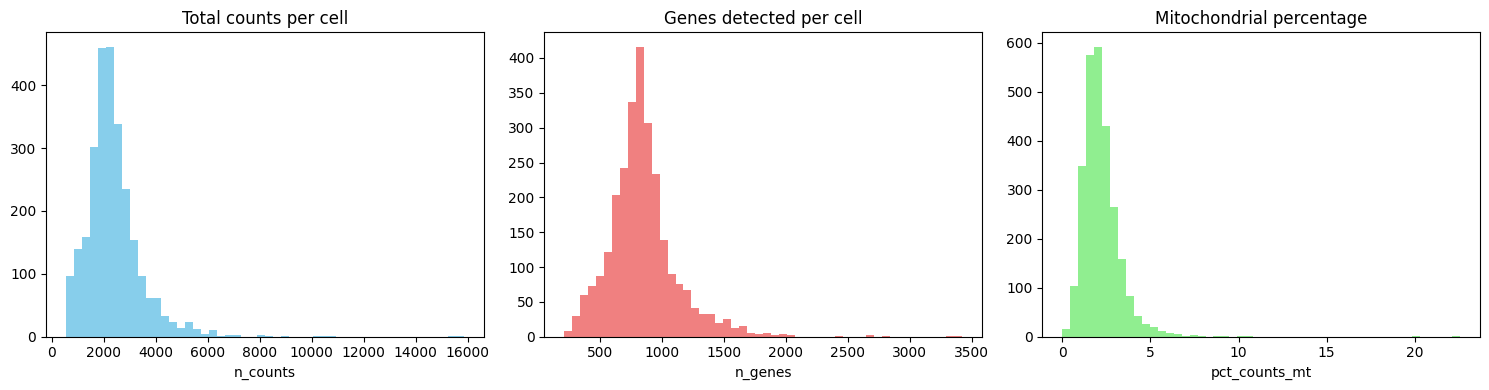

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(adata.obs["n_counts"], bins=50, color='skyblue')
axes[0].set_title("Total counts per cell")
axes[0].set_xlabel("n_counts")

axes[1].hist(adata.obs["n_genes"], bins=50, color='lightcoral')
axes[1].set_title("Genes detected per cell")
axes[1].set_xlabel("n_genes")

axes[2].hist(adata.obs["pct_counts_mt"], bins=50, color='lightgreen')
axes[2].set_title("Mitochondrial percentage")
axes[2].set_xlabel("pct_counts_mt")

plt.tight_layout()
plt.show()

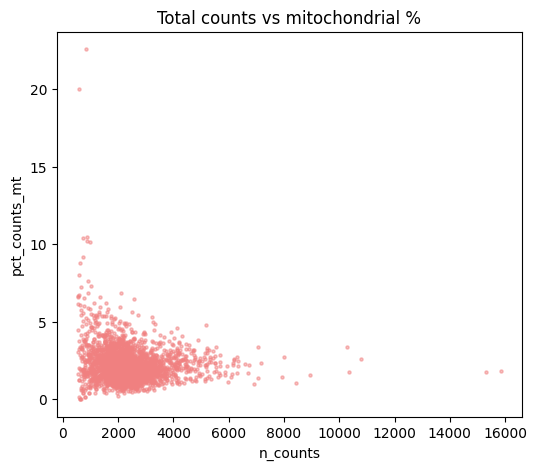

In [ ]:
plt.figure(figsize=(6, 5))
plt.scatter(adata.obs["n_counts"], adata.obs["pct_counts_mt"], s=5, alpha=0.5, color="lightcoral")
plt.xlabel("n_counts")
plt.ylabel("pct_counts_mt")
plt.title("Total counts vs mitochondrial %")
plt.show()

In [ ]:
min_counts = 500
min_genes = 200
max_pct_mt = 10

keep = (
    (adata.obs["n_counts"] >= min_counts) &
    (adata.obs["n_genes"] >= min_genes) &
    (adata.obs["pct_counts_mt"] <= max_pct_mt)
)

print(keep.sum(), "cells pass QC out of", len(keep))

2694 cells pass QC out of 2700


In [ ]:
adata_filtered_X = adata.X[keep.values, :]
adata_filtered_obs = adata.obs[keep.values].copy()

adata = CellForgeData(adata_filtered_X, adata_filtered_obs, adata.var)
print(adata)

CellForgeData: 2694 cells x 32738 genes


# **NORMALIZATION**

In [ ]:
import numpy as np

In [ ]:
new_row_sums = np.asarray(X_norm.sum(axis=1)).flatten()
print(new_row_sums[:5])

[10000. 10000. 10000. 10000. 10000.]


In [ ]:
# Find a row with plenty of non-zero values to inspect
row_idx = 1  # cell with high n_counts (4903) from earlier — should have lots of nonzero genes
row_norm = X_norm[row_idx].toarray().flatten()
row_lognorm = X_lognorm[row_idx].toarray().flatten()

nonzero_positions = np.nonzero(row_norm)[0][:10]  # first 10 nonzero gene positions

print("normalized:   ", row_norm[nonzero_positions])
print("log-normalized:", row_lognorm[nonzero_positions])

normalized:    [4.07913522 2.03956761 2.03956761 4.07913522 2.03956761 2.03956761
 6.11870283 2.03956761 4.07913522 2.03956761]
log-normalized: [1.62514102 1.11171527 1.11171527 1.62514102 1.11171527 1.11171527
 1.96272552 1.11171527 1.62514102 1.11171527]


In [ ]:
adata.layers["counts"] = adata.X.copy()   # keep raw counts around, unchanged
adata.layers["lognorm"] = X_lognorm       # the normalized + log-transformed version

print(adata.layers.keys())
print(adata)

dict_keys(['counts', 'lognorm'])
CellForgeData: 2694 cells x 32738 genes


# **Highly Variable Gene Selection**

In [ ]:
X_lognorm = adata.layers["lognorm"]

gene_mean = np.asarray(X_lognorm.mean(axis=0)).flatten()

# variance per gene: E[X^2] - (E[X])^2
gene_mean_sq = np.asarray(X_lognorm.multiply(X_lognorm).mean(axis=0)).flatten()
gene_var = gene_mean_sq - gene_mean**2

adata.var["mean"] = gene_mean
adata.var["variance"] = gene_var

print(adata.var[["mean", "variance"]].describe())

               mean      variance
count  32738.000000  32738.000000
mean       0.052426      0.059842
std        0.245959      0.168940
min        0.000000      0.000000
25%        0.000000      0.000000
50%        0.000452      0.000550
75%        0.021028      0.035551
max        5.431340      3.598268


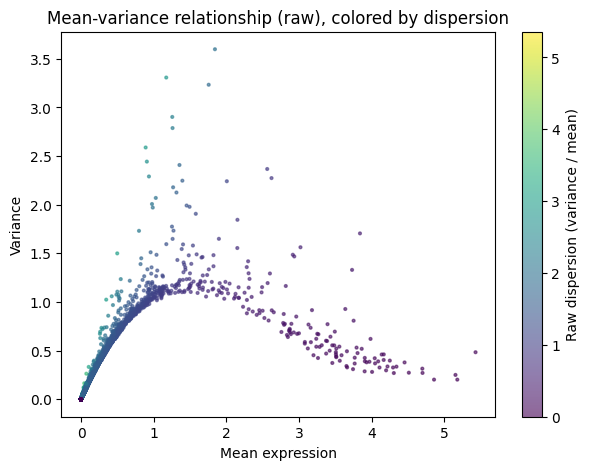

In [ ]:
dispersion_raw = adata.var["variance"] / (adata.var["mean"] + 1e-12)

plt.figure(figsize=(7, 5))
sc = plt.scatter(
    adata.var["mean"],
    adata.var["variance"],
    c=dispersion_raw,
    cmap="viridis",
    s=4,
    alpha=0.6
)
plt.colorbar(sc, label="Raw dispersion (variance / mean)")
plt.xlabel("Mean expression")
plt.ylabel("Variance")
plt.title("Mean-variance relationship (raw), colored by dispersion")
plt.show()

In [ ]:
n_bins = 20

# Bin genes by mean expression
adata.var["mean_bin"] = pd.qcut(adata.var["mean"], n_bins, labels=False, duplicates="drop")

adata.var["dispersion"] = dispersion_raw

# Within each bin, z-score the dispersion
bin_stats = adata.var.groupby("mean_bin")["dispersion"].agg(["mean", "std"])
print(bin_stats)

              mean       std
mean_bin                    
0         0.015929  0.126899
1         1.661172  0.256919
2         1.687637  0.340793
3         1.710666  0.231205
4         1.713252  0.185797
5         1.702093  0.142339
6         1.689297  0.101190
7         1.678719  0.112940
8         1.659771  0.090364
9         1.611902  0.081621
10        1.326690  0.397731


In [ ]:
adata.var = adata.var.merge(
    bin_stats.rename(columns={"mean": "bin_mean", "std": "bin_std"}),
    left_on="mean_bin", right_index=True, how="left"
)

adata.var["dispersion_norm"] = (
    (adata.var["dispersion"] - adata.var["bin_mean"]) / adata.var["bin_std"]
)

print(adata.var[["mean", "dispersion", "mean_bin", "dispersion_norm"]].sort_values(
    "dispersion_norm", ascending=False
).head(15))

                  mean  dispersion  mean_bin  dispersion_norm
PPBP          0.073367    3.579157         8        21.240686
IGLL5         0.106312    3.124763         9        18.535221
PF4           0.044755    3.663568         7        17.574331
GNG11         0.036488    3.326751         7        14.592067
SDPR          0.039263    3.091806         7        12.511810
GP9           0.017978    3.347812         5        11.561981
MICALCL       0.001989    5.357383         2        10.768248
GJC3          0.001950    5.252256         2        10.459770
HBA1          0.022061    2.744834         6        10.431244
SPARC         0.031643    2.709989         6        10.086895
CLU           0.039763    2.775218         7         9.708666
CTA-797E19.2  0.000452    1.217370         0         9.467698
DACT3         0.000452    1.217370         0         9.467698
RAB26         0.000452    1.216701         0         9.462421
PDE6A         0.000452    1.216701         0         9.462421


In [ ]:
n_cells_expressing = np.asarray((adata.layers["lognorm"] > 0).sum(axis=0)).flatten()
adata.var["n_cells_expressing"] = n_cells_expressing

min_cells = 3
print((adata.var["n_cells_expressing"] >= min_cells).sum(), "genes pass min-cell filter")

13712 genes pass min-cell filter


In [ ]:
mask = adata.var["n_cells_expressing"] >= min_cells
var_filtered = adata.var[mask].copy()

n_bins = 20
var_filtered["mean_bin"] = pd.qcut(var_filtered["mean"], n_bins, labels=False, duplicates="drop")

bin_stats2 = var_filtered.groupby("mean_bin")["dispersion"].agg(["mean", "std"])
var_filtered = var_filtered.merge(
    bin_stats2.rename(columns={"mean": "bin_mean2", "std": "bin_std2"}),
    left_on="mean_bin", right_index=True, how="left"
)

var_filtered["dispersion_norm2"] = (
    (var_filtered["dispersion"] - var_filtered["bin_mean2"]) / var_filtered["bin_std2"]
)

print(var_filtered["mean_bin"].value_counts().sort_index())
print(var_filtered[["mean", "dispersion", "mean_bin", "dispersion_norm2"]].sort_values(
    "dispersion_norm2", ascending=False
).head(15))

mean_bin
0     686
1     686
2     685
3     686
4     685
5     686
6     685
7     686
8     685
9     686
10    686
11    685
12    686
13    685
14    686
15    685
16    686
17    685
18    686
19    686
Name: count, dtype: int64
               mean  dispersion  mean_bin  dispersion_norm2
PPBP       0.073367    3.579157        13         17.048985
IGLL5      0.106312    3.124763        15         17.003853
PF4        0.044755    3.663568        11         16.115559
GNG11      0.036488    3.326751        10         13.839683
SDPR       0.039263    3.091806        10         11.853308
GP9        0.017978    3.347812         7         11.694164
SPARC      0.031643    2.709989         9         11.317770
GZMB       0.346976    2.950266        18         10.002542
SPON2      0.174373    2.221724        17          9.311776
LINC00926  0.178993    2.215120        17          9.216923
CD9        0.058687    2.364985        12          9.186364
IGJ        0.055754    2.356243        12    

In [ ]:
n_top_genes = 2000

top_genes = var_filtered.sort_values("dispersion_norm2", ascending=False).head(n_top_genes).index

adata.var["highly_variable"] = adata.var.index.isin(top_genes)

print(adata.var["highly_variable"].sum(), "genes selected as highly variable")
print(adata.var[adata.var["highly_variable"]][["mean", "dispersion_norm2" if "dispersion_norm2" in adata.var.columns else "dispersion"]].describe() if False else "")

2015 genes selected as highly variable



In [ ]:
print(adata.var.loc[adata.var["highly_variable"], "mean"].describe())

count    2015.000000
mean        0.080709
std         0.164707
min         0.000000
25%         0.005758
50%         0.025411
75%         0.078773
max         1.843795
Name: mean, dtype: float64


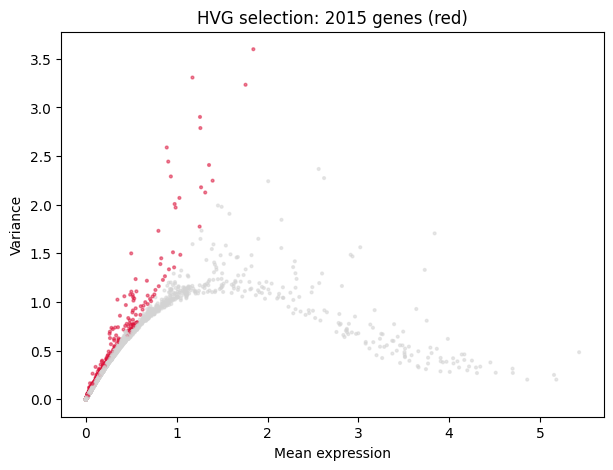

In [ ]:
plt.figure(figsize=(7, 5))
colors = adata.var["highly_variable"].map({True: "crimson", False: "lightgray"})
plt.scatter(adata.var["mean"], adata.var["variance"], c=colors, s=4, alpha=0.5)
plt.xlabel("Mean expression")
plt.ylabel("Variance")
plt.title(f"HVG selection: {adata.var['highly_variable'].sum()} genes (red)")
plt.show()

In [ ]:
hvg_mask = adata.var["highly_variable"].values
X_hvg = adata.layers["lognorm"][:, hvg_mask]

print(X_hvg.shape)

(2694, 2015)


# **NORMALISATION**

In [ ]:
gene_means = X_dense.mean(axis=0)
gene_stds = X_dense.std(axis=0)

# Avoid divide-by-zero for any gene with zero variance (shouldn't happen post-HVG, but safe to guard)
gene_stds[gene_stds == 0] = 1.0

X_scaled = (X_dense - gene_means) / gene_stds

print(X_scaled.mean(axis=0)[:5])
print(X_scaled.std(axis=0)[:5])

[-4.09059901e-16  8.40064634e-16  4.09224745e-16 -9.48490647e-16
 -3.97809312e-16]
[1. 1. 1. 1. 1.]


In [ ]:
n_cells = X_scaled.shape[0]

eigenvalues = (S ** 2) / (n_cells - 1)
explained_variance_ratio = eigenvalues / eigenvalues.sum()

# Cell coordinates in PCA space = U * S
X_pca_full = U * S

print(explained_variance_ratio[:10])
print(explained_variance_ratio[:10].sum())
print(X_pca_full.shape)

[0.02171336 0.01584997 0.01199248 0.00867205 0.00459769 0.00360386
 0.00335808 0.00296995 0.00284794 0.0025491 ]
0.07815449193783379
(2694, 2000)


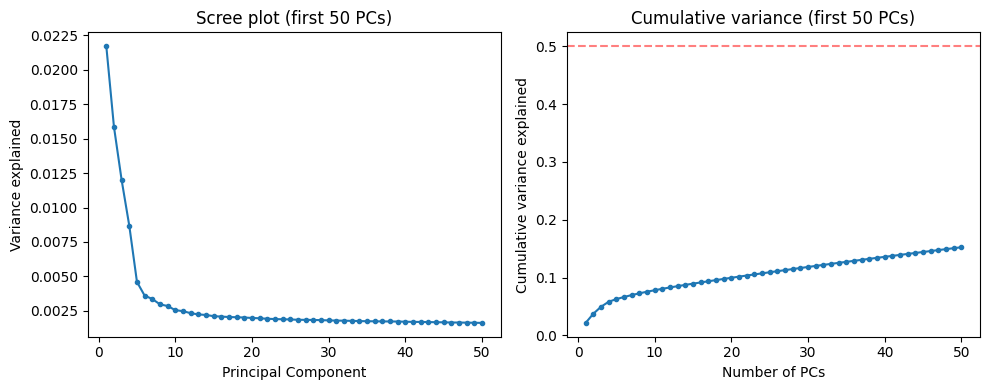

In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, 51), explained_variance_ratio[:50], marker='o', markersize=3)
plt.xlabel("Principal Component")
plt.ylabel("Variance explained")
plt.title("Scree plot (first 50 PCs)")

plt.subplot(1, 2, 2)
cumulative_variance = np.cumsum(explained_variance_ratio)
plt.plot(range(1, 51), cumulative_variance[:50], marker='o', markersize=3)
plt.xlabel("Number of PCs")
plt.ylabel("Cumulative variance explained")
plt.title("Cumulative variance (first 50 PCs)")
plt.axhline(y=0.5, color='r', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.decomposition import PCA

pca_sklearn = PCA(n_components=n_pcs, svd_solver="full")
X_pca_sklearn = pca_sklearn.fit_transform(X_scaled)

print("Our explained variance ratio (first 5):", explained_variance_ratio[:5])
print("sklearn explained variance ratio (first 5):", pca_sklearn.explained_variance_ratio_[:5])

# Compare actual coordinates - note: sign of PCs is arbitrary in SVD, so compare magnitudes
print("\nOur PC1 (first 5 cells):", X_pca[:5, 0])
print("sklearn PC1 (first 5 cells):", X_pca_sklearn[:5, 0])

Our explained variance ratio (first 5): [0.02171336 0.01584997 0.01199248 0.00867205 0.00459769]
sklearn explained variance ratio (first 5): [0.02171336 0.01584997 0.01199248 0.00867205 0.00459769]

Our PC1 (first 5 cells): [-4.85875834 -2.00145301 -4.35993192 11.76888438 -5.48655402]
sklearn PC1 (first 5 cells): [-4.85875834 -2.00145301 -4.35993192 11.76888438 -5.48655402]


# **K-Nearest-Neighbor Graph Construction**

In [ ]:
k = 15  # a common default for scRNA-seq KNN graphs

# For each row, get indices of the k+1 smallest distances (k+1 because the cell itself is always closest, at distance 0)
knn_indices = np.argsort(dist_matrix, axis=1)[:, 1:k+1]  # skip column 0 (self)
knn_distances = np.take_along_axis(dist_matrix, knn_indices, axis=1)

print(knn_indices.shape)
print(knn_indices[0])
print(knn_distances[0])

(2694, 15)
[1369 2127 1297 2499  140 1724 2152 2389 2479  487 1253 2256 1800 2052
 1094]
[3.41310922 3.42307176 3.5180605  3.5192213  3.58232725 3.58923923
 3.68167042 3.69470296 3.75296517 3.79500342 3.79685035 3.8279517
 3.92562466 3.94303795 3.96075045]


In [ ]:
from scipy.sparse import csr_matrix

n_cells = X_pca.shape[0]

row_indices = np.repeat(np.arange(n_cells), k)  # [0,0,...,0 (15 times), 1,1,...,1, ...]
col_indices = knn_indices.flatten()             # the actual neighbor indices, flattened
data = np.ones(n_cells * k)                     # just 1s — unweighted graph for now

knn_graph = csr_matrix((data, (row_indices, col_indices)), shape=(n_cells, n_cells))

print(knn_graph.shape)
print(knn_graph.nnz)
print(knn_graph[0].nonzero())

(2694, 2694)
40410
(array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=int32), array([ 140,  487, 1094, 1253, 1297, 1369, 1724, 1800, 2052, 2127, 2152,
       2256, 2389, 2479, 2499], dtype=int32))


In [ ]:
knn_graph_symmetric = knn_graph.maximum(knn_graph.T)

print(knn_graph_symmetric.shape)
print(knn_graph_symmetric.nnz)

# Check: is it actually symmetric now?
diff = (knn_graph_symmetric - knn_graph_symmetric.T)
print("Max difference (should be 0):", np.abs(diff).max())

(2694, 2694)
69238
Max difference (should be 0): 0.0


# **Graph-Based Clustering**

In [ ]:
degrees = np.asarray(knn_graph_symmetric.sum(axis=1)).flatten()
m = knn_graph_symmetric.sum() / 2  # each edge counted twice in a symmetric adjacency matrix

print(degrees[:10])
print(m)

[57. 24. 17. 37. 22. 20. 37. 17. 15. 18.]
34619.0


In [ ]:
n_cells = knn_graph_symmetric.shape[0]
cluster_labels = np.arange(n_cells)  # cluster_labels[i] = i, meaning cell i starts alone in cluster i

print(cluster_labels[:10])
print(len(np.unique(cluster_labels)))

[0 1 2 3 4 5 6 7 8 9]
2694


In [ ]:
def get_neighbors_and_clusters(node, graph, cluster_labels):
    neighbors = graph[node].nonzero()[1]  # column indices of nonzero entries in this node's row
    neighbor_clusters = cluster_labels[neighbors]
    return neighbors, neighbor_clusters

# Try it on node 0
neighbors, neighbor_clusters = get_neighbors_and_clusters(0, knn_graph_symmetric, cluster_labels)
print(neighbors)
print(neighbor_clusters)

[   7   42  140  210  316  355  371  389  404  457  487  580  690  737
  782  841  846  848 1012 1022 1094 1107 1168 1180 1204 1253 1266 1287
 1297 1304 1369 1409 1464 1470 1513 1546 1641 1710 1724 1739 1800 1831
 1946 1980 2052 2114 2127 2152 2256 2284 2299 2354 2389 2433 2479 2499
 2683]
[   7   42  140  210  316  355  371  389  404  457  487  580  690  737
  782  841  846  848 1012 1022 1094 1107 1168 1180 1204 1253 1266 1287
 1297 1304 1369 1409 1464 1470 1513 1546 1641 1710 1724 1739 1800 1831
 1946 1980 2052 2114 2127 2152 2256 2284 2299 2354 2389 2433 2479 2499
 2683]


In [ ]:
def compute_modularity_gain(node, candidate_cluster, graph, cluster_labels, degrees, m):
    # Sigma_in: edges from node to nodes already in candidate_cluster (excluding node itself)
    neighbors = graph[node].nonzero()[1]
    neighbor_clusters = cluster_labels[neighbors]
    sigma_in = np.sum(neighbor_clusters == candidate_cluster)

    # Sigma_tot: sum of degrees of all nodes currently in candidate_cluster
    members_of_cluster = np.where(cluster_labels == candidate_cluster)[0]
    sigma_tot = degrees[members_of_cluster].sum()

    k_i = degrees[node]

    delta_q = (sigma_in / m) - (k_i * sigma_tot) / (2 * m**2)
    return delta_q

# Test: gain from moving node 0 into node 7's cluster (candidate_cluster = 7, since cluster labels = node indices right now)
gain = compute_modularity_gain(0, 7, knn_graph_symmetric, cluster_labels, degrees, m)
print(gain)

2.8481608222500323e-05


In [ ]:
def find_best_move(node, graph, cluster_labels, degrees, m):
    neighbors = graph[node].nonzero()[1]
    neighbor_clusters = np.unique(cluster_labels[neighbors])

    current_cluster = cluster_labels[node]
    best_gain = 0.0
    best_cluster = current_cluster

    for candidate in neighbor_clusters:
        if candidate == current_cluster:
            continue
        gain = compute_modularity_gain(node, candidate, graph, cluster_labels, degrees, m)
        if gain > best_gain:
            best_gain = gain
            best_cluster = candidate

    return best_cluster, best_gain

best_cluster, best_gain = find_best_move(0, knn_graph_symmetric, cluster_labels, degrees, m)
print(best_cluster, best_gain)

1012 2.852916865750545e-05


In [ ]:
def run_one_pass(graph, cluster_labels, degrees, m):
    n_cells = len(cluster_labels)
    n_moves = 0

    for node in range(n_cells):
        best_cluster, best_gain = find_best_move(node, graph, cluster_labels, degrees, m)
        if best_gain > 1e-10:  # small threshold to avoid floating-point noise triggering "moves" with ~0 gain
            cluster_labels[node] = best_cluster
            n_moves += 1

    return cluster_labels, n_moves

cluster_labels, n_moves = run_one_pass(knn_graph_symmetric, cluster_labels, degrees, m)

print("Moves made:", n_moves)
print("Unique clusters remaining:", len(np.unique(cluster_labels)))

Moves made: 2694
Unique clusters remaining: 574


In [ ]:
def compute_total_modularity(graph, cluster_labels, degrees, m):
    unique_clusters = np.unique(cluster_labels)
    Q = 0.0
    for c in unique_clusters:
        members = np.where(cluster_labels == c)[0]
        # edges within this cluster (both directions counted, so this naturally gives 2*internal_edges)
        subgraph = graph[members][:, members]
        internal_edges = subgraph.sum() / 2
        sigma_tot = degrees[members].sum()
        Q += (internal_edges / m) - (sigma_tot / (2 * m)) ** 2
    return Q

# Check modularity of your current (interrupted) partition
Q_current = compute_total_modularity(knn_graph_symmetric, cluster_labels, degrees, m)
print("Current modularity:", Q_current)

Current modularity: 0.3726319168161717


In [ ]:
max_passes = 50
tolerance = 1e-5
prev_Q = compute_total_modularity(knn_graph_symmetric, cluster_labels, degrees, m)

for pass_num in range(max_passes):
    cluster_labels, n_moves = run_one_pass(knn_graph_symmetric, cluster_labels, degrees, m)
    Q = compute_total_modularity(knn_graph_symmetric, cluster_labels, degrees, m)
    n_clusters = len(np.unique(cluster_labels))
    print(f"Pass {pass_num + 1}: {n_moves} moves, {n_clusters} clusters, Q = {Q:.6f}")

    if Q - prev_Q < tolerance:
        print("Converged (modularity plateaued).")
        break
    prev_Q = Q

Pass 1: 2693 moves, 21 clusters, Q = 0.368821
Converged (modularity plateaued).


In [ ]:
max_passes = 50
tolerance = 1e-5

best_Q = compute_total_modularity(knn_graph_symmetric, cluster_labels, degrees, m)
best_labels = cluster_labels.copy()

for pass_num in range(max_passes):
    cluster_labels, n_moves = run_one_pass(knn_graph_symmetric, cluster_labels, degrees, m)
    Q = compute_total_modularity(knn_graph_symmetric, cluster_labels, degrees, m)
    n_clusters = len(np.unique(cluster_labels))
    print(f"Pass {pass_num + 1}: {n_moves} moves, {n_clusters} clusters, Q = {Q:.6f}")

    if Q > best_Q + tolerance:
        best_Q = Q
        best_labels = cluster_labels.copy()
    else:
        print(f"No further improvement (best Q = {best_Q:.6f}). Stopping.")
        break

cluster_labels = best_labels
final_Q = compute_total_modularity(knn_graph_symmetric, cluster_labels, degrees, m)
print("\nFinal clusters:", len(np.unique(cluster_labels)))
print("Final modularity:", final_Q)

Pass 1: 2694 moves, 21 clusters, Q = 0.373220
Pass 2: 2694 moves, 21 clusters, Q = 0.369313
No further improvement (best Q = 0.373220). Stopping.

Final clusters: 21
Final modularity: 0.3732204463267971


In [ ]:
!pip install leidenalg python-igraph -q

sc.tl.leiden(adata_sc, resolution=1.0, flavor="igraph", n_iterations=2, directed=False)

print("Scanpy Leiden clusters:", adata_sc.obs["leiden"].nunique())
print(adata_sc.obs["leiden"].value_counts())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 26.3 MB/s eta 0:00:00
Scanpy Leiden clusters: 11
leiden
5     697
8     450
3     377
1     349
0     263
6     218
7     150
10    143
9      32
4       8
2       7
Name: count, dtype: int64


In [ ]:
def collapse_graph(graph, cluster_labels):
    unique_clusters = np.unique(cluster_labels)
    n_super = len(unique_clusters)

    label_to_idx = {label: idx for idx, label in enumerate(unique_clusters)}
    mapped_labels = np.array([label_to_idx[l] for l in cluster_labels])

    from scipy.sparse import coo_matrix

    graph_coo = graph.tocoo()
    super_row = mapped_labels[graph_coo.row]
    super_col = mapped_labels[graph_coo.col]

    super_graph = coo_matrix(
        (graph_coo.data, (super_row, super_col)),
        shape=(n_super, n_super)
    ).tocsr()

    return super_graph, mapped_labels, unique_clusters

super_graph, mapped_labels, unique_clusters = collapse_graph(knn_graph_symmetric, cluster_labels)

print("Super-graph shape:", super_graph.shape)
print("Super-graph total edge weight:", super_graph.sum())
print("Original graph total edge weight:", knn_graph_symmetric.sum())

Super-graph shape: (21, 21)
Super-graph total edge weight: 69238.0
Original graph total edge weight: 69238.0


In [ ]:
super_degrees = np.asarray(super_graph.sum(axis=1)).flatten()
super_m = super_graph.sum() / 2

print(super_degrees)
print(super_m)

[2911.  475. 2361. 3439. 1853. 9787. 4877. 2048. 1514. 4776. 2223. 2069.
 4146. 2605. 1455. 3648. 5531. 4194.   63. 2658. 6605.]
34619.0


In [ ]:
super_cluster_labels = np.arange(super_graph.shape[0])  # each super-node starts in its own cluster

best_Q = compute_total_modularity(super_graph, super_cluster_labels, super_degrees, super_m)
best_labels = super_cluster_labels.copy()

max_passes = 50
for pass_num in range(max_passes):
    super_cluster_labels, n_moves = run_one_pass(super_graph, super_cluster_labels, super_degrees, super_m)
    Q = compute_total_modularity(super_graph, super_cluster_labels, super_degrees, super_m)
    n_clusters = len(np.unique(super_cluster_labels))
    print(f"Pass {pass_num + 1}: {n_moves} moves, {n_clusters} super-clusters, Q = {Q:.6f}")

    if Q > best_Q + 1e-5:
        best_Q = Q
        best_labels = super_cluster_labels.copy()
    else:
        print(f"No further improvement (best Q = {best_Q:.6f}). Stopping.")
        break

super_cluster_labels = best_labels
print("\nFinal super-clusters:", len(np.unique(super_cluster_labels)))
print("Final modularity (on super-graph):", best_Q)

Pass 1: 0 moves, 21 super-clusters, Q = 0.373220
No further improvement (best Q = 0.373220). Stopping.

Final super-clusters: 21
Final modularity (on super-graph): 0.3732204463267971


In [ ]:
def run_one_pass_randomized(graph, cluster_labels, degrees, m, rng):
    n_cells = len(cluster_labels)
    node_order = rng.permutation(n_cells)  # shuffled processing order
    n_moves = 0

    for node in node_order:
        best_cluster, best_gain = find_best_move(node, graph, cluster_labels, degrees, m)
        if best_gain > 1e-10:
            cluster_labels[node] = best_cluster
            n_moves += 1

    return cluster_labels, n_moves


def full_louvain_from_scratch(graph, degrees, m, seed, max_passes=50):
    rng = np.random.default_rng(seed)
    cluster_labels = np.arange(graph.shape[0])

    best_Q = compute_total_modularity(graph, cluster_labels, degrees, m)
    best_labels = cluster_labels.copy()

    for pass_num in range(max_passes):
        cluster_labels, n_moves = run_one_pass_randomized(graph, cluster_labels, degrees, m, rng)
        Q = compute_total_modularity(graph, cluster_labels, degrees, m)

        if Q > best_Q + 1e-5:
            best_Q = Q
            best_labels = cluster_labels.copy()
        else:
            break

    return best_labels, best_Q


# Run multiple trials with different random seeds on the ORIGINAL cell-level graph
results = []
for seed in range(10):
    labels, Q = full_louvain_from_scratch(knn_graph_symmetric, degrees, m, seed=seed)
    n_clusters = len(np.unique(labels))
    results.append((seed, n_clusters, Q))
    print(f"Seed {seed}: {n_clusters} clusters, Q = {Q:.6f}")

Seed 0: 27 clusters, Q = 0.377824
Seed 1: 545 clusters, Q = 0.315882
Seed 2: 43 clusters, Q = 0.361505
Seed 3: 23 clusters, Q = 0.374413
Seed 4: 32 clusters, Q = 0.363665
Seed 5: 28 clusters, Q = 0.367367
Seed 6: 30 clusters, Q = 0.371947
Seed 7: 41 clusters, Q = 0.350829
Seed 8: 72 clusters, Q = 0.345887
Seed 9: 35 clusters, Q = 0.365040


In [ ]:
def full_louvain_robust(graph, degrees, m, max_passes=100, patience=5, tol=1e-4):
    cluster_labels = np.arange(graph.shape[0])
    best_Q = compute_total_modularity(graph, cluster_labels, degrees, m)
    best_labels = cluster_labels.copy()
    stale_passes = 0

    for pass_num in range(max_passes):
        cluster_labels, n_moves = run_one_pass(graph, cluster_labels, degrees, m)
        Q = compute_total_modularity(graph, cluster_labels, degrees, m)

        if Q > best_Q + tol:
            best_Q = Q
            best_labels = cluster_labels.copy()
            stale_passes = 0
        else:
            stale_passes += 1

        print(f"Pass {pass_num + 1}: {n_moves} moves, {len(np.unique(cluster_labels))} clusters, Q = {Q:.6f}")

        if n_moves == 0 or stale_passes >= patience:
            print(f"Stopping (stale_passes={stale_passes}). Best Q = {best_Q:.6f}")
            break

    return best_labels, best_Q

final_best_labels, final_best_Q = full_louvain_robust(knn_graph_symmetric, degrees, m)

print("\nFinal clusters:", len(np.unique(final_best_labels)))
print("Final modularity:", final_best_Q)

adata.obs["cluster"] = final_best_labels.astype(str)
print(adata.obs["cluster"].value_counts())

Pass 1: 2694 moves, 574 clusters, Q = 0.268346
Pass 2: 2694 moves, 104 clusters, Q = 0.342859
Pass 3: 2694 moves, 45 clusters, Q = 0.338367
Pass 4: 2694 moves, 29 clusters, Q = 0.351907
Pass 5: 2694 moves, 27 clusters, Q = 0.357516
Pass 6: 2694 moves, 26 clusters, Q = 0.364607
Pass 7: 2694 moves, 23 clusters, Q = 0.366122
Pass 8: 2694 moves, 22 clusters, Q = 0.369086
Pass 9: 2694 moves, 22 clusters, Q = 0.367634
Pass 10: 2694 moves, 21 clusters, Q = 0.371241
Pass 11: 2694 moves, 21 clusters, Q = 0.366558
Pass 12: 2694 moves, 21 clusters, Q = 0.370528
Pass 13: 2694 moves, 21 clusters, Q = 0.369016
Pass 14: 2694 moves, 21 clusters, Q = 0.372058
Pass 15: 2694 moves, 21 clusters, Q = 0.367933
Pass 16: 2694 moves, 21 clusters, Q = 0.371152
Pass 17: 2694 moves, 21 clusters, Q = 0.367806
Pass 18: 2694 moves, 21 clusters, Q = 0.370913
Pass 19: 2694 moves, 21 clusters, Q = 0.368074
Stopping (stale_passes=5). Best Q = 0.372058

Final clusters: 21
Final modularity: 0.37205808431435644
cluster
108

# **UMAP**

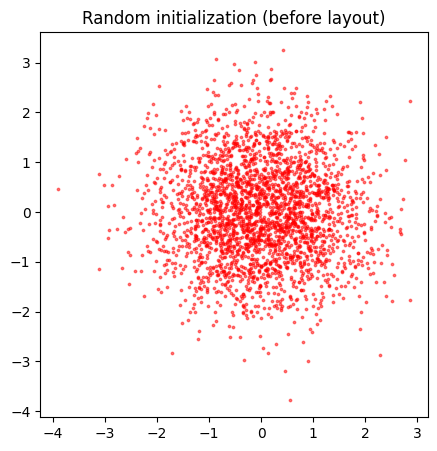

In [ ]:
n_cells = knn_graph_symmetric.shape[0]
rng = np.random.default_rng(0)

X_umap = rng.normal(scale=1.0, size=(n_cells, 2))

plt.figure(figsize=(5, 5))
plt.scatter(X_umap[:, 0], X_umap[:, 1], s=3, alpha=0.5, color='red')
plt.title("Random initialization (before layout)")
plt.show()

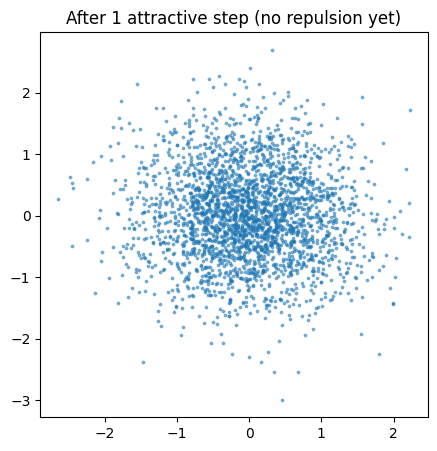

In [ ]:
def attractive_step(X_umap, graph, learning_rate=0.01):
    graph_coo = graph.tocoo()
    rows, cols = graph_coo.row, graph_coo.col

    # Vector from each point to its neighbor
    delta = X_umap[cols] - X_umap[rows]

    # Move each point a small step toward its neighbor
    updates = np.zeros_like(X_umap)
    np.add.at(updates, rows, learning_rate * delta)

    return X_umap + updates

# Test: one attractive step
X_umap_test = attractive_step(X_umap, knn_graph_symmetric)

plt.figure(figsize=(5, 5))
plt.scatter(X_umap_test[:, 0], X_umap_test[:, 1], s=3, alpha=0.5)
plt.title("After 1 attractive step (no repulsion yet)")
plt.show()

In [ ]:
import time

X_umap = rng.normal(scale=1.0, size=(n_cells, 2))

n_iterations = 50
for i in range(n_iterations):
    t0 = time.time()
    X_umap = attractive_step(X_umap, knn_graph_symmetric, learning_rate=0.01)
    X_umap = repulsive_step(X_umap, learning_rate=0.001)
    t1 = time.time()
    print(f"Iteration {i}: mean magnitude = {np.abs(X_umap).mean():.3f}, time = {t1-t0:.2f}s")

Iteration 0: mean magnitude = 1.450, time = 1.54s
Iteration 1: mean magnitude = 1.549, time = 1.00s
Iteration 2: mean magnitude = 1.618, time = 0.80s
Iteration 3: mean magnitude = 1.670, time = 0.79s
Iteration 4: mean magnitude = 1.712, time = 0.77s
Iteration 5: mean magnitude = 1.747, time = 0.76s
Iteration 6: mean magnitude = 1.778, time = 0.65s
Iteration 7: mean magnitude = 1.807, time = 0.57s
Iteration 8: mean magnitude = 1.837, time = 0.57s
Iteration 9: mean magnitude = 1.867, time = 0.54s
Iteration 10: mean magnitude = 1.900, time = 0.55s
Iteration 11: mean magnitude = 1.935, time = 0.55s
Iteration 12: mean magnitude = 1.973, time = 0.54s
Iteration 13: mean magnitude = 2.014, time = 0.57s
Iteration 14: mean magnitude = 2.060, time = 0.55s
Iteration 15: mean magnitude = 2.112, time = 0.57s
Iteration 16: mean magnitude = 2.167, time = 0.55s
Iteration 17: mean magnitude = 2.228, time = 0.69s
Iteration 18: mean magnitude = 2.294, time = 0.75s
Iteration 19: mean magnitude = 2.364, tim

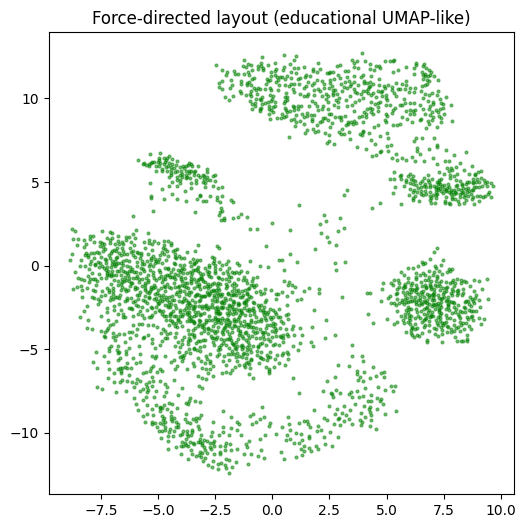

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(X_umap[:, 0], X_umap[:, 1], s=4, alpha=0.5, color='green')
plt.title("Force-directed layout (educational UMAP-like)")
plt.show()

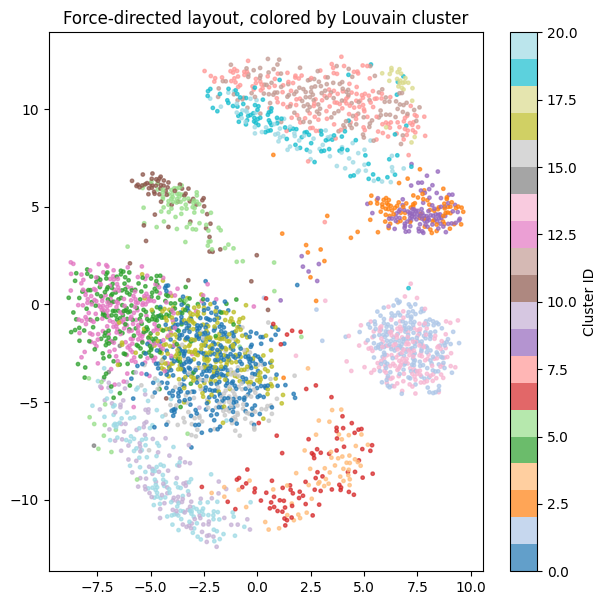

In [ ]:
cluster_ids = adata.obs["cluster"].astype("category").cat.codes

plt.figure(figsize=(7, 7))
scatter = plt.scatter(X_umap[:, 0], X_umap[:, 1], c=cluster_ids, cmap="tab20", s=6, alpha=0.7)
plt.title("Force-directed layout, colored by Louvain cluster")
plt.colorbar(scatter, label="Cluster ID")
plt.show()

Iteration 0: lr_attract=0.0200, mean magnitude=2.894
Iteration 20: lr_attract=0.0160, mean magnitude=49.162
Iteration 40: lr_attract=0.0120, mean magnitude=89.792
Iteration 60: lr_attract=0.0080, mean magnitude=4.892
Iteration 80: lr_attract=0.0040, mean magnitude=5.408


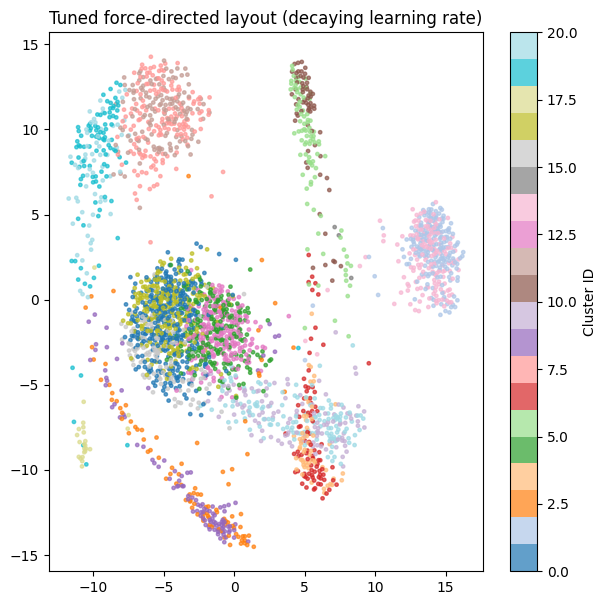

In [ ]:
X_umap = rng.normal(scale=1.0, size=(n_cells, 2))

n_iterations = 100
initial_lr_attract = 0.02
initial_lr_repel = 0.002

for i in range(n_iterations):
    decay = 1.0 - (i / n_iterations)  # linearly decay from 1.0 down to ~0
    lr_attract = initial_lr_attract * decay
    lr_repel = initial_lr_repel * decay

    X_umap = attractive_step(X_umap, knn_graph_symmetric, learning_rate=lr_attract)
    X_umap = repulsive_step(X_umap, learning_rate=lr_repel)

    if i % 20 == 0:
        print(f"Iteration {i}: lr_attract={lr_attract:.4f}, mean magnitude={np.abs(X_umap).mean():.3f}")

plt.figure(figsize=(7, 7))
scatter = plt.scatter(X_umap[:, 0], X_umap[:, 1], c=cluster_ids, cmap="tab20", s=6, alpha=0.7)
plt.title("Tuned force-directed layout (decaying learning rate)")
plt.colorbar(scatter, label="Cluster ID")
plt.show()

Iteration 0: mean magnitude=7.721
Iteration 20: mean magnitude=85.828
Iteration 40: mean magnitude=149.463
Iteration 60: mean magnitude=8.678
Iteration 80: mean magnitude=9.651


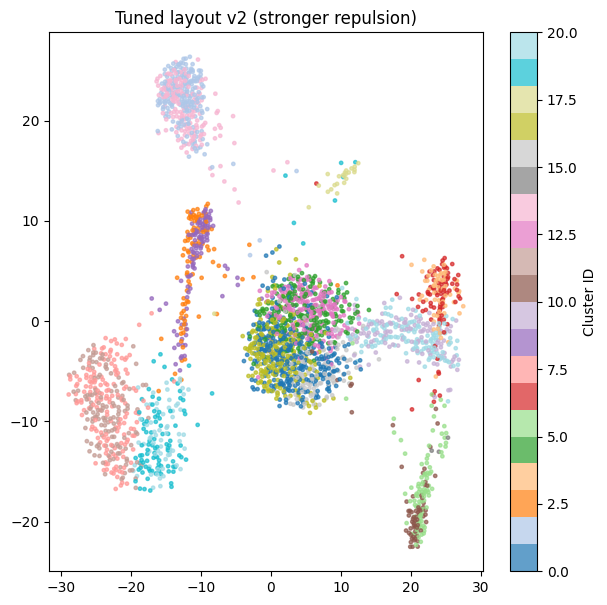

In [ ]:
X_umap = rng.normal(scale=1.0, size=(n_cells, 2))

n_iterations = 100
initial_lr_attract = 0.02
initial_lr_repel = 0.006  # tripled from 0.002 — stronger push-apart force

for i in range(n_iterations):
    decay = 1.0 - (i / n_iterations)
    lr_attract = initial_lr_attract * decay
    lr_repel = initial_lr_repel * decay

    X_umap = attractive_step(X_umap, knn_graph_symmetric, learning_rate=lr_attract)
    X_umap = repulsive_step(X_umap, learning_rate=lr_repel)

    if i % 20 == 0:
        print(f"Iteration {i}: mean magnitude={np.abs(X_umap).mean():.3f}")

plt.figure(figsize=(7, 7))
scatter = plt.scatter(X_umap[:, 0], X_umap[:, 1], c=cluster_ids, cmap="tab20", s=6, alpha=0.7)
plt.title("Tuned layout v2 (stronger repulsion)")
plt.colorbar(scatter, label="Cluster ID")
plt.show()

# **DIFFERENTIAL EXPRESSION**

In [ ]:
from scipy.stats import ranksums

test_cluster = "0"
gene_idx = 0

in_cluster = (adata.obs["cluster"] == test_cluster).values
X_lognorm_dense_col = np.asarray(adata.layers["lognorm"][:, gene_idx].todense()).flatten()

group_a = X_lognorm_dense_col[in_cluster]
group_b = X_lognorm_dense_col[~in_cluster]

stat, pvalue = ranksums(group_a, group_b)

print("Cluster size:", in_cluster.sum(), "| Rest size:", (~in_cluster).sum())
print("Statistic:", stat, "P-value:", pvalue)

Cluster size: 332 | Rest size: 2362
Statistic: 0.0 P-value: 1.0


In [ ]:
gene_names = np.array(adata.var.index)
ppbp_idx = np.where(gene_names == "PPBP")[0][0]
print("PPBP index:", ppbp_idx)

# Test PPBP across a few different clusters to see if any show strong signal
for cluster_id in adata.obs["cluster"].unique():
    in_cluster = (adata.obs["cluster"] == cluster_id).values
    gene_vals = np.asarray(adata.layers["lognorm"][:, ppbp_idx].todense()).flatten()
    group_a = gene_vals[in_cluster]
    group_b = gene_vals[~in_cluster]
    stat, pvalue = ranksums(group_a, group_b)
    print(f"Cluster {cluster_id}: n={in_cluster.sum()}, stat={stat:.2f}, p={pvalue:.2e}")

PPBP index: 7696
Cluster 19: n=132, stat=-0.45, p=6.54e-01
Cluster 13: n=157, stat=-0.37, p=7.12e-01
Cluster 4: n=209, stat=-0.52, p=6.06e-01
Cluster 18: n=99, stat=0.71, p=4.75e-01
Cluster 10: n=64, stat=-0.41, p=6.81e-01
Cluster 9: n=113, stat=-0.38, p=7.02e-01
Cluster 2: n=96, stat=2.58, p=1.00e-02
Cluster 16: n=229, stat=-0.45, p=6.56e-01
Cluster 7: n=167, stat=0.56, p=5.73e-01
Cluster 1: n=196, stat=-0.23, p=8.19e-01
Cluster 15: n=117, stat=-0.24, p=8.13e-01
Cluster 0: n=332, stat=-0.28, p=7.82e-01
Cluster 12: n=208, stat=-0.52, p=6.07e-01
Cluster 11: n=140, stat=0.13, p=8.93e-01
Cluster 5: n=92, stat=-0.50, p=6.20e-01
Cluster 8: n=106, stat=1.37, p=1.70e-01
Cluster 17: n=23, stat=0.11, p=9.13e-01
Cluster 6: n=87, stat=-0.29, p=7.70e-01
Cluster 20: n=65, stat=0.23, p=8.19e-01
Cluster 3: n=59, stat=-0.17, p=8.69e-01
Cluster 14: n=3, stat=-0.09, p=9.30e-01


In [ ]:
def rank_genes_for_cluster(adata, cluster_id, layer="lognorm"):
    in_cluster = (adata.obs["cluster"] == cluster_id).values
    X = adata.layers[layer]

    n_genes = X.shape[1]
    stats = np.zeros(n_genes)
    pvalues = np.ones(n_genes)

    X_dense = X.toarray()  # 2694 x 32738 -- let's check this is feasible first

    group_a = X_dense[in_cluster, :]
    group_b = X_dense[~in_cluster, :]

    for g in range(n_genes):
        stat, p = ranksums(group_a[:, g], group_b[:, g])
        stats[g] = stat
        pvalues[g] = p

    return stats, pvalues

# Time just cluster "2" to see how long a full run takes for one cluster
import time
t0 = time.time()
stats_c2, pvalues_c2 = rank_genes_for_cluster(adata, "2")
t1 = time.time()
print(f"Time for one cluster, all genes: {t1-t0:.1f}s")

Time for one cluster, all genes: 33.8s


In [ ]:
all_de_results = {}

t0 = time.time()
for cluster_id in sorted(adata.obs["cluster"].unique(), key=int):
    stats, pvalues = rank_genes_for_cluster_fast(adata, cluster_id)
    all_de_results[cluster_id] = {"stat": stats, "pvalue": pvalues}
    print(f"Cluster {cluster_id} done")
t1 = time.time()

print(f"\nTotal time: {t1-t0:.1f}s")

Cluster 0 done
Cluster 1 done
Cluster 2 done
Cluster 3 done
Cluster 4 done
Cluster 5 done
Cluster 6 done
Cluster 7 done
Cluster 8 done
Cluster 9 done
Cluster 10 done
Cluster 11 done
Cluster 12 done
Cluster 13 done
Cluster 14 done
Cluster 15 done
Cluster 16 done
Cluster 17 done
Cluster 18 done
Cluster 19 done
Cluster 20 done

Total time: 128.2s


In [ ]:
gene_names_arr = np.array(adata.var.index)

def get_top_markers(cluster_id, n_top=10):
    stats = all_de_results[cluster_id]["stat"]
    pvalues = all_de_results[cluster_id]["pvalue"]

    # Sort by statistic descending (most upregulated first), among significant genes
    significant = pvalues < 0.05
    order = np.argsort(-stats)
    order = order[significant[order]]

    top_genes = gene_names_arr[order[:n_top]]
    top_stats = stats[order[:n_top]]
    top_pvals = pvalues[order[:n_top]]

    return pd.DataFrame({"gene": top_genes, "stat": top_stats, "pvalue": top_pvals})

# Check a few clusters, including cluster 2 (our suspected platelet cluster)
for cid in ["2", "0", "16"]:
    print(f"\n=== Cluster {cid} top markers ===")
    print(get_top_markers(cid))


=== Cluster 2 top markers ===
     gene       stat  pvalue
0  FCER1G  14.189205     0.0
1    LST1  13.692424     0.0
2    SAT1  13.682803     0.0
3    AIF1  13.679597     0.0
4    FTH1  13.455524     0.0
5   COTL1  13.247619     0.0
6    OAZ1  13.139724     0.0
7  IFITM3  12.897613     0.0
8     FTL  12.871091     0.0
9    PSAP  12.615284     0.0

=== Cluster 0 top markers ===
    gene       stat  pvalue
0  RPS12  16.686083     0.0
1  RPL32  16.563822     0.0
2   RPS6  16.537298     0.0
3  RPS14  15.754566     0.0
4  RPS27  15.739872     0.0
5  RPL31  15.258741     0.0
6  RPS25  15.048769     0.0
7   LDHB  14.195431     0.0
8  RPLP2  14.091556     0.0
9  RPL21  14.000379     0.0

=== Cluster 16 top markers ===
     gene       stat  pvalue
0   RPS27  14.204763     0.0
1   RPS25  13.685019     0.0
2    RPS6  12.919214     0.0
3   RPS12  12.830266     0.0
4   RPL32  12.826802     0.0
5   RPLP2  12.717338     0.0
6   RPS13  12.376778     0.0
7  RPS15A  12.250394     0.0
8    LDHB  11.9937

In [ ]:
technical_genes = ["RPLP2", "RPSA", "TPT1", "EEF1A1", "MALAT1", "NPM1"]
is_technical = adata.var.index.str.match(r"^RP[SL]\d") | adata.var.index.isin(technical_genes)
print("Technical/ribosomal genes excluded:", is_technical.sum())

for cid in ["0", "16"]:
    print(f"\n=== Cluster {cid} top markers (technical genes excluded) ===")
    print(get_top_markers_filtered(cid, exclude_mask=is_technical))

Technical/ribosomal genes excluded: 107

=== Cluster 0 top markers (technical genes excluded) ===
      gene       stat  pvalue
0     LDHB  14.195431     0.0
1     CD3E  11.071999     0.0
2     CD3D  10.743157     0.0
3     CCR7  10.443477     0.0
4   TMEM66  10.370874     0.0
5  C6orf48   9.653774     0.0
6     JUNB   9.611991     0.0
7   EEF1B2   9.468217     0.0
8    RPLP0   9.462339     0.0
9     BTG1   9.041340     0.0

=== Cluster 16 top markers (technical genes excluded) ===
      gene       stat        pvalue
0     LDHB  11.993764  0.000000e+00
1    NOSIP   8.604594  0.000000e+00
2      LTB   8.421991  0.000000e+00
3     JUNB   8.326915  0.000000e+00
4  GLTSCR2   8.237567  2.220446e-16
5     CD3D   8.020681  1.110223e-15
6     CD3E   8.017884  1.110223e-15
7    RPLP0   7.461326  8.570922e-14
8   TMEM66   7.405462  1.307843e-13
9     CCR7   7.404795  1.314504e-13


In [ ]:
# Broader, more principled ribosomal gene pattern:
# catches RPS/RPL followed by any digit OR by P (like RPLP0, RPLP1, RPLP2)
is_ribosomal_v2 = adata.var.index.str.match(r"^RP[SL]([0-9]|P[0-9])")

# Common mitochondrial genes (already have this from Module 2, but let's exclude them from DE too)
is_mito = adata.var.index.str.startswith("MT-")

# A short, well-established list of near-universal housekeeping/technical genes
# that commonly dominate DE results without being true identity markers
housekeeping_genes = [
    "MALAT1", "EEF1A1", "EEF1B2", "EEF2", "TPT1", "NPM1", "FTL", "FTH1",
    "ACTB", "ACTG1", "GAPDH", "B2M", "TMSB4X", "TMSB10"
]
is_housekeeping = adata.var.index.isin(housekeeping_genes)

is_technical_final = is_ribosomal_v2 | is_mito | is_housekeeping
print("Total technical genes excluded:", is_technical_final.sum())

Total technical genes excluded: 131


In [ ]:
def get_top_markers_filtered(cluster_id, n_top=10, exclude_mask=is_technical_final):
    stats = all_de_results[cluster_id]["stat"].copy()
    pvalues = all_de_results[cluster_id]["pvalue"]

    stats[exclude_mask] = -np.inf

    significant = pvalues < 0.05
    order = np.argsort(-stats)
    order = order[significant[order] & (~exclude_mask[order])]

    return pd.DataFrame({
        "gene": gene_names_arr[order[:n_top]],
        "stat": stats[order[:n_top]],
        "pvalue": pvalues[order[:n_top]]
    })

all_top_markers = {}
for cid in sorted(adata.obs["cluster"].unique(), key=int):
    all_top_markers[cid] = get_top_markers_filtered(cid, n_top=8)
    print(f"\n=== Cluster {cid} ===")
    print(all_top_markers[cid]["gene"].tolist())


=== Cluster 0 ===
['LDHB', 'RPSA', 'CD3E', 'CD3D', 'CCR7', 'TMEM66', 'C6orf48', 'JUNB']

=== Cluster 1 ===
['CD74', 'CD79A', 'HLA-DRA', 'HLA-DQA1', 'CD79B', 'HLA-DPB1', 'MS4A1', 'HLA-DRB1']

=== Cluster 2 ===
['FCER1G', 'LST1', 'SAT1', 'AIF1', 'COTL1', 'OAZ1', 'IFITM3', 'PSAP']

=== Cluster 3 ===
['CCL5', 'NKG7', 'CST7', 'GZMH', 'HLA-C', 'CD3D', 'GZMA', 'CTSW']

=== Cluster 4 ===
['IL32', 'LDHB', 'LTB', 'CD3D', 'IL7R', 'CD2', 'RPSA', 'CD3E']

=== Cluster 5 ===
['NKG7', 'GZMB', 'CTSW', 'GNLY', 'GZMA', 'CST7', 'PRF1', 'HLA-C']

=== Cluster 6 ===
['NKG7', 'CCL5', 'CST7', 'GZMH', 'HLA-C', 'GZMA', 'HLA-A', 'CTSW']

=== Cluster 7 ===
['S100A8', 'S100A9', 'LYZ', 'TYROBP', 'S100A6', 'LGALS1', 'FCN1', 'GPX1']

=== Cluster 8 ===
['COTL1', 'LST1', 'SAT1', 'AIF1', 'FCER1G', 'OAZ1', 'IFITM3', 'FCGR3A']

=== Cluster 9 ===
['CCL5', 'IL32', 'GZMK', 'NKG7', 'CTSW', 'GZMA', 'LYAR', 'PTPRCAP']

=== Cluster 10 ===
['PRF1', 'NKG7', 'GZMB', 'FGFBP2', 'GNLY', 'GZMA', 'CST7', 'CTSW']

=== Cluster 11 ===
['S1

# **CELL TYPE ANNOTATION**

In [ ]:
marker_reference = {
    "Naive/Memory T cell": ["CD3D", "CD3E", "CD3G", "IL7R", "CCR7", "LTB"],
    "Cytotoxic T / NK cell": ["NKG7", "GZMA", "GZMB", "GZMH", "GZMK", "GNLY", "CST7", "PRF1"],
    "B cell": ["CD79A", "CD79B", "MS4A1", "CD74"],
    "Monocyte": ["LYZ", "S100A8", "S100A9", "FCN1", "CST3", "AIF1", "FCER1G"],
    "Dendritic cell": ["HLA-DRA", "HLA-DPB1", "HLA-DPA1", "HLA-DQA1", "FCER1A"],
    "Platelet": ["PPBP", "PF4", "GNG11", "SDPR", "GP9"],
}

# Check which marker genes actually exist in our gene list (avoid silent errors from typos/missing genes)
for cell_type, markers in marker_reference.items():
    missing = [g for g in markers if g not in adata.var.index]
    print(f"{cell_type}: {len(markers)} markers, missing: {missing}")

Naive/Memory T cell: 6 markers, missing: []
Cytotoxic T / NK cell: 8 markers, missing: []
B cell: 4 markers, missing: []
Monocyte: 7 markers, missing: []
Dendritic cell: 5 markers, missing: []
Platelet: 5 markers, missing: []


In [ ]:
def score_cluster_for_celltype(cluster_id, markers, adata, layer="lognorm"):
    marker_indices = [np.where(gene_names_arr == g)[0][0] for g in markers]
    in_cluster = (adata.obs["cluster"] == cluster_id).values

    X_dense = adata.layers[layer][:, marker_indices].toarray()

    mean_in_cluster = X_dense[in_cluster, :].mean()
    mean_outside = X_dense[~in_cluster, :].mean()

    return mean_in_cluster - mean_outside  # simple, interpretable score

# Build a full scoring matrix: rows = clusters, columns = cell types
cluster_ids_sorted = sorted(adata.obs["cluster"].unique(), key=int)
score_matrix = pd.DataFrame(index=cluster_ids_sorted, columns=marker_reference.keys(), dtype=float)

for cluster_id in cluster_ids_sorted:
    for cell_type, markers in marker_reference.items():
        score_matrix.loc[cluster_id, cell_type] = score_cluster_for_celltype(cluster_id, markers, adata)

print(score_matrix.round(2))

    Naive/Memory T cell  Cytotoxic T / NK cell  B cell  Monocyte  \
0                  0.64                  -0.43   -0.63     -0.89   
1                 -0.37                  -0.40    2.36     -0.91   
2                 -0.73                  -0.29    0.15      1.65   
3                  0.13                   1.68   -0.35     -0.90   
4                  0.71                  -0.32   -0.49     -0.86   
5                 -0.62                   2.44   -0.38     -0.57   
6                  0.02                   1.66   -0.37     -0.88   
7                 -0.86                  -0.40   -0.23      2.83   
8                 -0.77                  -0.34    0.13      1.65   
9                  0.42                   0.58   -0.44     -0.87   
10                -0.72                   2.46   -0.25     -0.49   
11                -0.87                  -0.39   -0.18      2.86   
12                 0.76                  -0.35   -0.49     -0.84   
13                -0.36                  -0.42  

In [ ]:
best_celltype = score_matrix.idxmax(axis=1)
best_score = score_matrix.max(axis=1)

annotation_table = pd.DataFrame({
    "cluster": cluster_ids_sorted,
    "assigned_cell_type": best_celltype.values,
    "score": best_score.values,
    "cluster_size": [
        (adata.obs["cluster"] == cid).sum() for cid in cluster_ids_sorted
    ]
})

print(annotation_table.sort_values("cluster", key=lambda x: x.astype(int)).to_string(index=False))

cluster    assigned_cell_type    score  cluster_size
      0   Naive/Memory T cell 0.638007           332
      1                B cell 2.364822           196
      2              Monocyte 1.648866            96
      3 Cytotoxic T / NK cell 1.675135            59
      4   Naive/Memory T cell 0.713148           209
      5 Cytotoxic T / NK cell 2.437557            92
      6 Cytotoxic T / NK cell 1.658877            87
      7              Monocyte 2.830950           167
      8              Monocyte 1.645533           106
      9 Cytotoxic T / NK cell 0.580783           113
     10 Cytotoxic T / NK cell 2.462336            64
     11              Monocyte 2.857333           140
     12   Naive/Memory T cell 0.759570           208
     13                B cell 2.180282           157
     14 Cytotoxic T / NK cell 1.832963             3
     15   Naive/Memory T cell 0.489764           117
     16   Naive/Memory T cell 0.636991           229
     17        Dendritic cell 2.782200        

cell_type
Naive/Memory T cell      1095
Monocyte                  673
Cytotoxic T / NK cell     550
B cell                    353
Dendritic cell             23
Name: count, dtype: int64


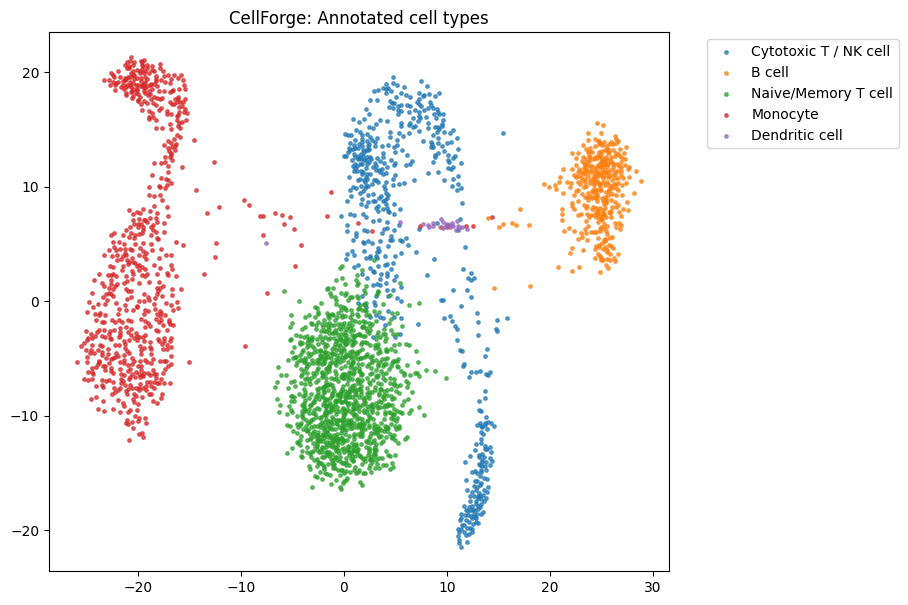

In [ ]:
cluster_to_celltype = dict(zip(annotation_table["cluster"], annotation_table["assigned_cell_type"]))
adata.obs["cell_type"] = adata.obs["cluster"].map(cluster_to_celltype)

print(adata.obs["cell_type"].value_counts())

# Visualize on our UMAP-like layout
plt.figure(figsize=(8, 7))
for cell_type in adata.obs["cell_type"].unique():
    mask = (adata.obs["cell_type"] == cell_type).values
    plt.scatter(X_umap[mask, 0], X_umap[mask, 1], label=cell_type, s=6, alpha=0.7)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title("CellForge: Annotated cell types")
plt.show()

# **VISUALISATION & REPORTING**

In [ ]:
marker_reference = {
    "Naive/Memory T cell": ["CD3D", "CD3E", "CD3G", "IL7R", "CCR7", "LTB"],
    "Cytotoxic T / NK cell": ["NKG7", "GZMA", "GZMB", "GZMH", "GZMK", "GNLY", "CST7", "PRF1"],
    "B cell": ["CD79A", "CD79B", "MS4A1", "CD74"],
    "Monocyte": ["LYZ", "S100A8", "S100A9", "FCN1", "CST3", "AIF1", "FCER1G"],
    "Dendritic cell": ["HLA-DRA", "HLA-DPB1", "HLA-DPA1", "HLA-DQA1", "FCER1A"],
    "Platelet": ["PPBP", "PF4", "GNG11", "SDPR", "GP9"],
}
def marker_dotplot(adata, marker_genes_by_type, layer="lognorm"):
    cluster_ids = sorted(adata.obs["cluster"].unique(), key=int)
    all_markers = [g for genes in marker_genes_by_type.values() for g in genes]
    gene_names_arr = np.array(adata.var.index)

    fraction_expressing = np.zeros((len(cluster_ids), len(all_markers)))
    mean_expression = np.zeros((len(cluster_ids), len(all_markers)))

    X = adata.layers[layer]

    for i, cluster_id in enumerate(cluster_ids):
        in_cluster = (adata.obs["cluster"] == cluster_id).values
        for j, gene in enumerate(all_markers):
            gene_idx = np.where(gene_names_arr == gene)[0][0]
            gene_vals = np.asarray(X[in_cluster, gene_idx].todense()).flatten()
            fraction_expressing[i, j] = (gene_vals > 0).mean()
            mean_expression[i, j] = gene_vals.mean()

    return cluster_ids, all_markers, fraction_expressing, mean_expression

# Test it using our existing marker reference
cluster_ids, all_markers, frac_expr, mean_expr = marker_dotplot(adata, marker_reference)
print("Shape check:", frac_expr.shape, "should be (21 clusters,", len(all_markers), "markers)")

Shape check: (21, 35) should be (21 clusters, 35 markers)


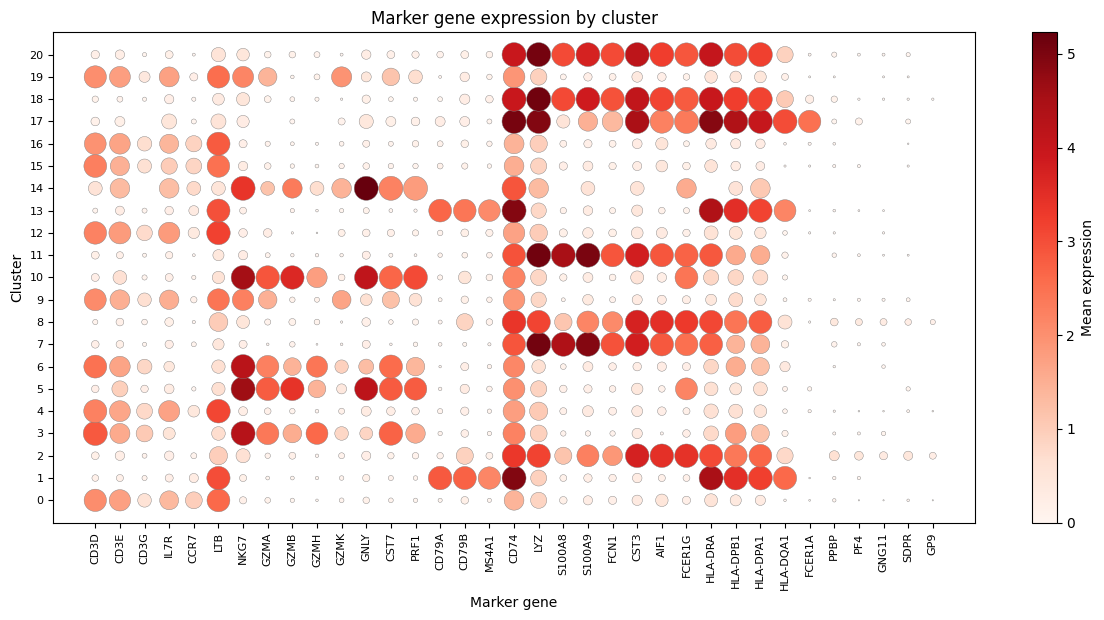

In [ ]:
def plot_marker_dotplot(cluster_ids, all_markers, fraction_expressing, mean_expression):
    n_clusters = len(cluster_ids)
    n_genes = len(all_markers)

    fig, ax = plt.subplots(figsize=(max(12, n_genes * 0.35), max(6, n_clusters * 0.3)))

    x_pos, y_pos, sizes, colors = [], [], [], []
    for i in range(n_clusters):
        for j in range(n_genes):
            x_pos.append(j)
            y_pos.append(i)
            sizes.append(fraction_expressing[i, j] * 300)  # scale for visibility
            colors.append(mean_expression[i, j])

    scatter = ax.scatter(x_pos, y_pos, s=sizes, c=colors, cmap="Reds", edgecolors="gray", linewidths=0.3)

    ax.set_xticks(range(n_genes))
    ax.set_xticklabels(all_markers, rotation=90, fontsize=8)
    ax.set_yticks(range(n_clusters))
    ax.set_yticklabels(cluster_ids, fontsize=8)
    ax.set_xlabel("Marker gene")
    ax.set_ylabel("Cluster")
    ax.set_title("Marker gene expression by cluster")

    cbar = plt.colorbar(scatter, ax=ax, label="Mean expression")

    plt.tight_layout()
    plt.show()

plot_marker_dotplot(cluster_ids, all_markers, frac_expr, mean_expr)

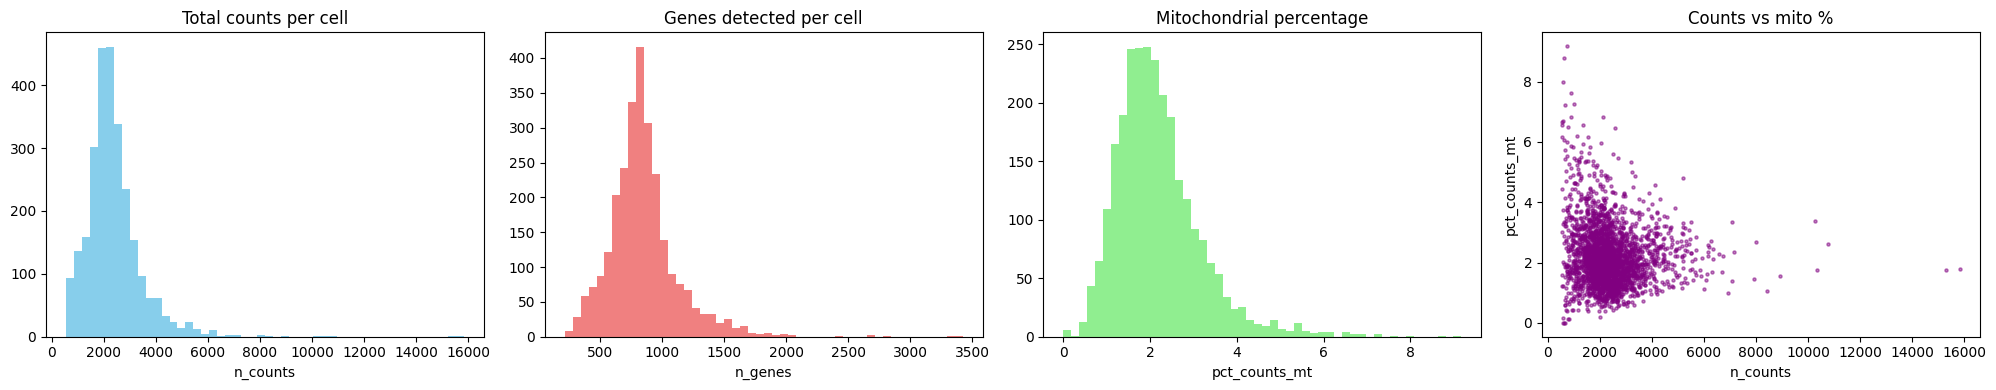

In [ ]:
def plot_qc_metrics(adata):
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))

    axes[0].hist(adata.obs["n_counts"], bins=50, color='skyblue') # Changed color
    axes[0].set_title("Total counts per cell")
    axes[0].set_xlabel("n_counts")

    axes[1].hist(adata.obs["n_genes"], bins=50, color='lightcoral') # Changed color
    axes[1].set_title("Genes detected per cell")
    axes[1].set_xlabel("n_genes")

    axes[2].hist(adata.obs["pct_counts_mt"], bins=50, color='lightgreen') # Changed color
    axes[2].set_title("Mitochondrial percentage")
    axes[2].set_xlabel("pct_counts_mt")

    axes[3].scatter(adata.obs["n_counts"], adata.obs["pct_counts_mt"], s=5, alpha=0.5, color='purple') # Changed color
    axes[3].set_xlabel("n_counts")
    axes[3].set_ylabel("pct_counts_mt")
    axes[3].set_title("Counts vs mito %")

    plt.tight_layout()
    plt.show()

plot_qc_metrics(adata)

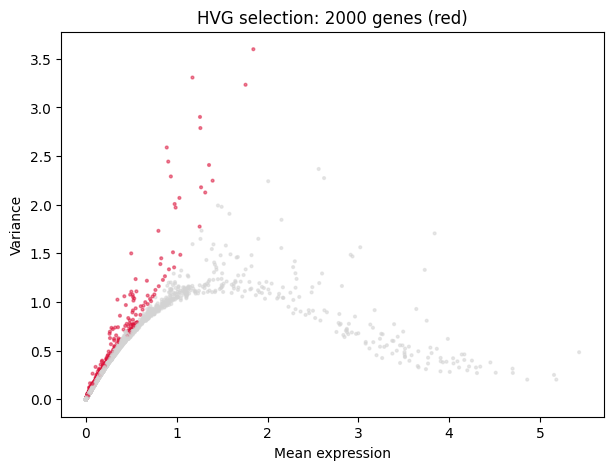

In [ ]:
def plot_hvg_selection(adata):
    plt.figure(figsize=(7, 5))
    colors = adata.var["highly_variable"].map({True: "crimson", False: "lightgray"})
    plt.scatter(adata.var["mean"], adata.var["variance"], c=colors, s=4, alpha=0.5)
    plt.xlabel("Mean expression")
    plt.ylabel("Variance")
    plt.title(f"HVG selection: {adata.var['highly_variable'].sum()} genes (red)")
    plt.show()

plot_hvg_selection(adata)

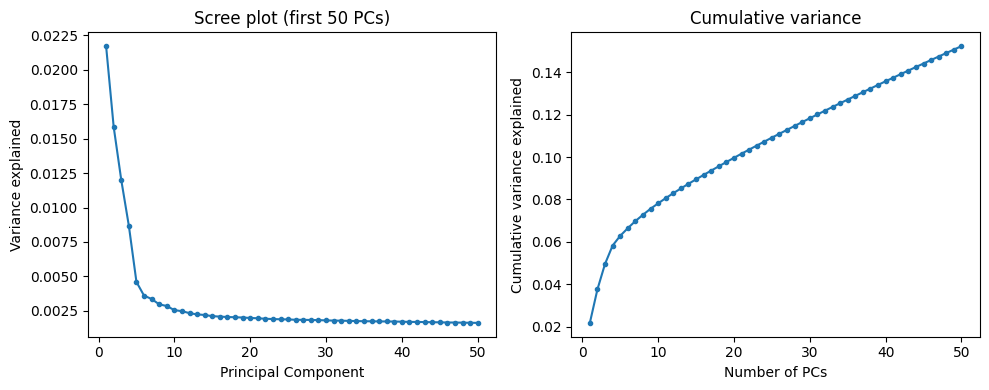

In [ ]:
def plot_pca_scree(explained_variance_ratio, n_show=50):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].plot(range(1, n_show + 1), explained_variance_ratio[:n_show], marker='o', markersize=3)
    axes[0].set_xlabel("Principal Component")
    axes[0].set_ylabel("Variance explained")
    axes[0].set_title(f"Scree plot (first {n_show} PCs)")

    cumulative = np.cumsum(explained_variance_ratio)
    axes[1].plot(range(1, n_show + 1), cumulative[:n_show], marker='o', markersize=3)
    axes[1].set_xlabel("Number of PCs")
    axes[1].set_ylabel("Cumulative variance explained")
    axes[1].set_title("Cumulative variance")

    plt.tight_layout()
    plt.show()

plot_pca_scree(explained_variance_ratio)

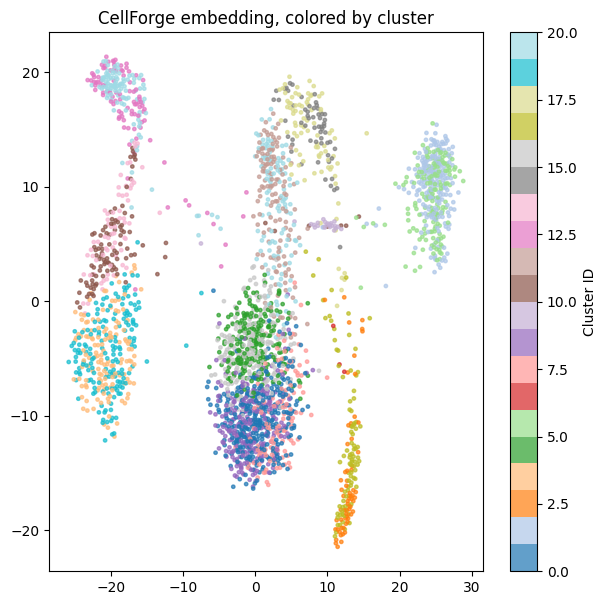

In [ ]:
def plot_embedding(adata, color_by="cluster", cmap="tab20"):
    X_umap = adata.obsm["X_umap"]

    if color_by == "cluster":
        labels = adata.obs["cluster"].astype("category").cat.codes
        plt.figure(figsize=(7, 7))
        scatter = plt.scatter(X_umap[:, 0], X_umap[:, 1], c=labels, cmap=cmap, s=6, alpha=0.7)
        plt.colorbar(scatter, label="Cluster ID")
    else:
        plt.figure(figsize=(8, 7))
        for category in adata.obs[color_by].unique():
            mask = (adata.obs[color_by] == category).values
            plt.scatter(X_umap[mask, 0], X_umap[mask, 1], label=category, s=6, alpha=0.7)
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

    plt.title(f"CellForge embedding, colored by {color_by}")
    plt.show()

plot_embedding(adata, color_by="cluster")

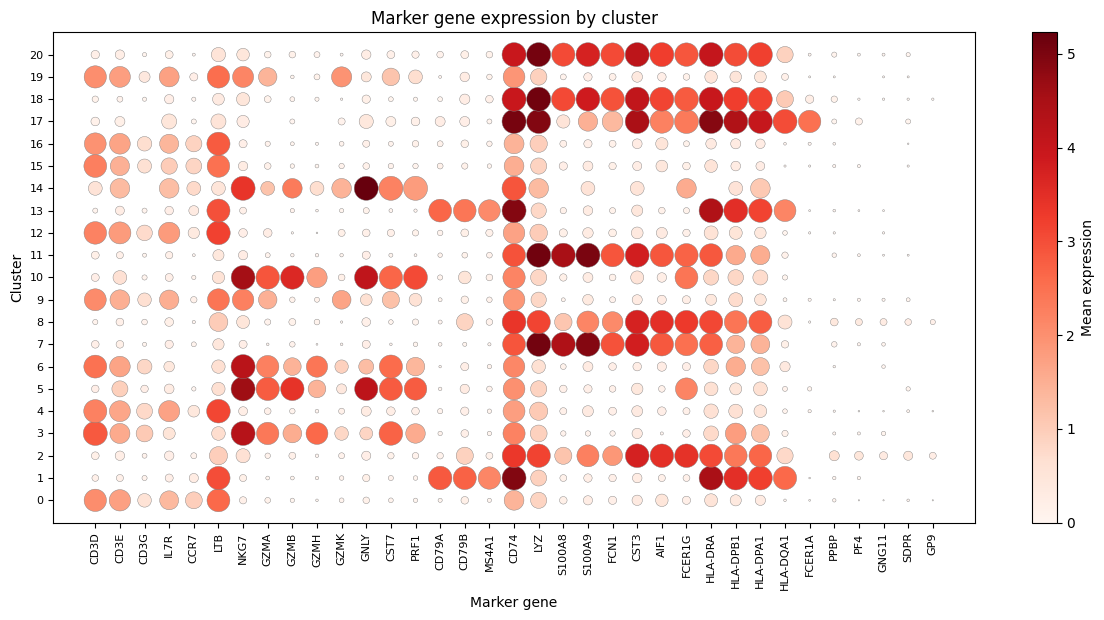

In [ ]:
def marker_dotplot(adata, marker_genes_by_type, layer="lognorm"):
    cluster_ids = sorted(adata.obs["cluster"].unique(), key=int)
    all_markers = [g for genes in marker_genes_by_type.values() for g in genes]
    gene_names_arr = np.array(adata.var.index)

    fraction_expressing = np.zeros((len(cluster_ids), len(all_markers)))
    mean_expression = np.zeros((len(cluster_ids), len(all_markers)))
    X = adata.layers[layer]

    for i, cluster_id in enumerate(cluster_ids):
        in_cluster = (adata.obs["cluster"] == cluster_id).values
        for j, gene in enumerate(all_markers):
            gene_idx = np.where(gene_names_arr == gene)[0][0]
            gene_vals = np.asarray(X[in_cluster, gene_idx].todense()).flatten()
            fraction_expressing[i, j] = (gene_vals > 0).mean()
            mean_expression[i, j] = gene_vals.mean()

    return cluster_ids, all_markers, fraction_expressing, mean_expression


def plot_marker_dotplot(cluster_ids, all_markers, fraction_expressing, mean_expression):
    n_clusters = len(cluster_ids)
    n_genes = len(all_markers)
    fig, ax = plt.subplots(figsize=(max(12, n_genes * 0.35), max(6, n_clusters * 0.3)))

    x_pos, y_pos, sizes, colors = [], [], [], []
    for i in range(n_clusters):
        for j in range(n_genes):
            x_pos.append(j)
            y_pos.append(i)
            sizes.append(fraction_expressing[i, j] * 300)
            colors.append(mean_expression[i, j])

    scatter = ax.scatter(x_pos, y_pos, s=sizes, c=colors, cmap="Reds", edgecolors="gray", linewidths=0.3)
    ax.set_xticks(range(n_genes))
    ax.set_xticklabels(all_markers, rotation=90, fontsize=8)
    ax.set_yticks(range(n_clusters))
    ax.set_yticklabels(cluster_ids, fontsize=8)
    ax.set_xlabel("Marker gene")
    ax.set_ylabel("Cluster")
    ax.set_title("Marker gene expression by cluster")
    plt.colorbar(scatter, ax=ax, label="Mean expression")
    plt.tight_layout()
    plt.show()


# Make sure marker_reference exists before running this
marker_reference = {
    "Naive/Memory T cell": ["CD3D", "CD3E", "CD3G", "IL7R", "CCR7", "LTB"],
    "Cytotoxic T / NK cell": ["NKG7", "GZMA", "GZMB", "GZMH", "GZMK", "GNLY", "CST7", "PRF1"],
    "B cell": ["CD79A", "CD79B", "MS4A1", "CD74"],
    "Monocyte": ["LYZ", "S100A8", "S100A9", "FCN1", "CST3", "AIF1", "FCER1G"],
    "Dendritic cell": ["HLA-DRA", "HLA-DPB1", "HLA-DPA1", "HLA-DQA1", "FCER1A"],
    "Platelet": ["PPBP", "PF4", "GNG11", "SDPR", "GP9"],
}

# Compute and plot
cluster_ids, all_markers, frac_expr, mean_expr = marker_dotplot(adata, marker_reference)
plot_marker_dotplot(cluster_ids, all_markers, frac_expr, mean_expr)

In [ ]:
def score_cluster_for_celltype(cluster_id, markers, adata, layer="lognorm"):
    gene_names_arr = np.array(adata.var.index)
    marker_indices = [np.where(gene_names_arr == g)[0][0] for g in markers]
    in_cluster = (adata.obs["cluster"] == cluster_id).values
    X_dense = adata.layers[layer][:, marker_indices].toarray()
    mean_in_cluster = X_dense[in_cluster, :].mean()
    mean_outside = X_dense[~in_cluster, :].mean()
    return mean_in_cluster - mean_outside

cluster_ids_sorted = sorted(adata.obs["cluster"].unique(), key=int)
score_matrix = pd.DataFrame(index=cluster_ids_sorted, columns=marker_reference.keys(), dtype=float)

for cluster_id in cluster_ids_sorted:
    for cell_type, markers in marker_reference.items():
        score_matrix.loc[cluster_id, cell_type] = score_cluster_for_celltype(cluster_id, markers, adata)

best_celltype = score_matrix.idxmax(axis=1)
cluster_to_celltype = dict(zip(cluster_ids_sorted, best_celltype.values))

adata.obs["cell_type"] = adata.obs["cluster"].map(cluster_to_celltype)
print(adata.obs["cell_type"].value_counts())

cell_type
Naive/Memory T cell      1095
Monocyte                  673
Cytotoxic T / NK cell     550
B cell                    353
Dendritic cell             23
Name: count, dtype: int64


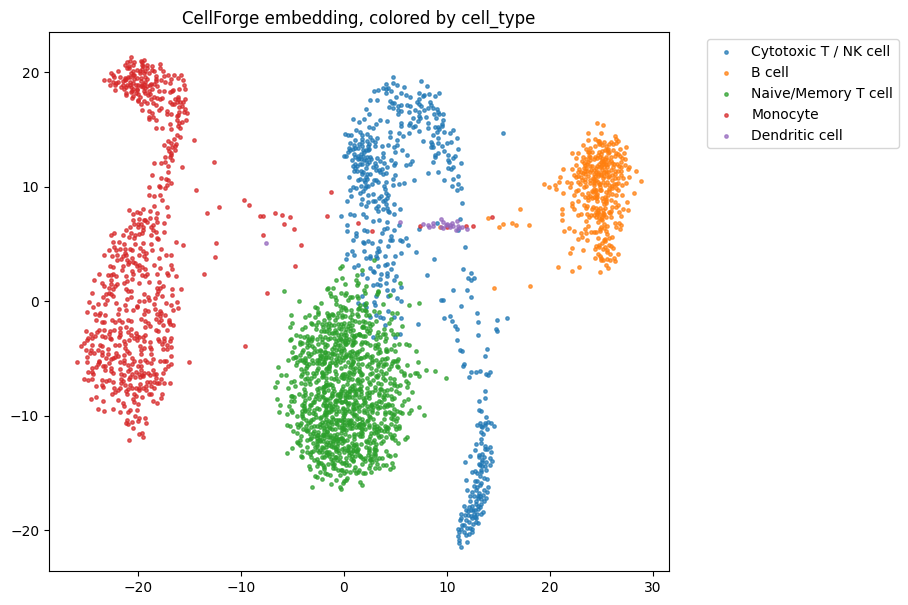

In [ ]:
plot_embedding(adata, color_by="cell_type")

In [1]:
import os

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in ["sample_data", ".git"]]
    for file in files:
        print(os.path.join(root, file))

/content/.config/.last_survey_prompt.yaml
/content/.config/active_config
/content/.config/.last_opt_in_prompt.yaml
/content/.config/config_sentinel
/content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/.config/gce
/content/.config/default_configs.db
/content/.config/.last_update_check.json
/content/.config/configurations/config_default
/content/.config/logs/2026.10.17/23.08.58.561612.log
/content/.config/logs/2026.10.17/23.08.21.541362.log
/content/.config/logs/2026.10.17/23.08.57.460113.log
/content/.config/logs/2026.10.17/23.08.48.139029.log
/content/.config/logs/2026.10.17/23.09.06.201823.log
/content/.config/logs/2026.10.17/23.09.06.764677.log


In [2]:
!git --version

git version 2.43.0


In [4]:
!git config --global user.name "ArryOnLoose"
!git config --global user.email "arsharchanaansh@gmail.com"

In [6]:
import os

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [".git", ".config", "sample_data"]]
    for f in files:
        if f.endswith((".ipynb", ".py")):
            print(os.path.join(root, f))

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    dirs[:] = [d for d in dirs if d not in ['.git', '__pycache__']]
    for f in files:
        if f.endswith('.ipynb') or f.endswith('.py'):
            print(os.path.join(root, f))

/content/drive/MyDrive/Colab Notebooks/CellForge.ipynb
/content/drive/MyDrive/Colab Notebooks/Diabetes.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/stack.ipynb
/content/drive/MyDrive/Colab Notebooks/separate#.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled1.ipynb
/content/drive/MyDrive/Colab Notebooks/binaryfile.ipynb
/content/drive/MyDrive/Colab Notebooks/pyProject.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled2.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled3.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled5.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled4.ipynb
/content/drive/MyDrive/Colab Notebooks/MBA PLACEMENT DATA ANALYSIS.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled6.ipynb
/content/drive/MyDrive/Colab Notebooks/BrainMRITumorPredictionSys.ipynb
/content/drive/MyDrive/Colab Notebooks/MBACA2.ipynb
/content/drive/MyDrive/Colab Notebooks/planaria2ipsc (1).ipynb
/content/drive/MyDrive/Colab 